# Analisis Keterkaitan Pupuk, Ekonomi, dan Iklim terhadap Produktivitas Serealia Antarnegara
*Sistem data end-to-end:* **World Bank API + NASA POWER → Apache Airflow → MySQL → notebook ini → dashboard → PPT**

## Latar belakang
Serealia (padi, jagung, gandum) adalah sumber kalori utama dunia, sehingga kemampuan sebuah negara menghasilkan serealia dari tiap hektare lahan (*produktivitas*) sangat memengaruhi ketahanan pangannya. Luas lahan saja tidak cukup menjelaskan: negara dengan lahan sempit bisa lebih produktif daripada negara berlahan luas. Perbedaan ini diduga berkaitan dengan input produksi (misalnya pupuk), struktur ekonomi, dan kondisi iklim.

Untuk Indonesia, yang pangan pokoknya beras dan sedang menghadapi tekanan lahan serta perubahan iklim, memahami faktor yang berkaitan dengan produktivitas membantu menilai posisi kita dibanding negara lain.

> **Catatan metodologi:** data ini observasional, jadi seluruh temuan adalah **keterkaitan (asosiasi)**, bukan bukti sebab-akibat.

## Tujuan
**Tujuan analisis**
1. Mengetahui negara dan kawasan dengan produktivitas serealia tertinggi, serta posisi Indonesia.
2. Mengetahui apakah pupuk, kondisi ekonomi, dan iklim berkaitan dengan produktivitas serealia.
3. Menguji apakah karakteristik sebuah negara cukup untuk mengklasifikasikan tingkat produktivitasnya (Rendah, Sedang, Tinggi).

**Tujuan teknis:** membangun sistem data end-to-end (API → Airflow → MySQL → notebook → dashboard) dengan penilaian dan pembersihan data yang benar.

## Empat pertanyaan
| # | Jenis | Pertanyaan |
|---|---|---|
| Q1 | Sederhana | Negara dan kawasan mana yang punya hasil serealia (kg/ha) tertinggi? |
| Q2 | Analisis | Apakah pemakaian pupuk berkaitan dengan hasil serealia? |
| Q3 | Analisis lanjutan | Apakah kondisi ekonomi (GDP per kapita) dan iklim (suhu, curah hujan) berkaitan dengan hasil serealia, dan bagaimana posisi Indonesia? |
| Q4 | Model AI | Dapatkah karakteristik pertanian, ekonomi, dan iklim dipakai untuk mengklasifikasikan tingkat hasil serealia (Rendah/Sedang/Tinggi)? |

## Alur notebook
1. Koneksi dan memuat data dari MySQL
2. Fungsi bantu dan aturan validitas
3. **Tabel `dim_country`**: assessing → cleaning → assessing ulang → EDA tabel
4. **Tabel `fact_agriculture`**: assessing → cleaning → assessing ulang → EDA tabel
5. **Tabel `fact_economic`**: assessing → cleaning → assessing ulang → EDA tabel
6. **Tabel `fact_climate`**: assessing → cleaning → assessing ulang → EDA tabel
7. **Menggabungkan** keempat tabel yang sudah bersih
8. **EDA data gabungan** menjawab Q1–Q3
9. **Model** menjawab Q4
10. Ekspor data bersih dan hasil model untuk dashboard

## Cara membaca notebook ini
Setiap sel kode diawali **satu baris label** dengan pola `# TAHAP | TABEL | ISI SEL`, supaya jelas sel itu tentang apa. Satu sel hanya mengerjakan satu hal, jadi keluarannya pendek.

| Label | Artinya |
|---|---|
| ⚙️ SETUP | Persiapan: impor library, koneksi database, fungsi bantu |
| 📘 PENJELASAN | Contoh untuk memahami struktur data dan konsep |
| 🔍 ASSESSING | Memeriksa kondisi data **sebelum** dibersihkan |
| 🧹 CLEANING | Satu langkah pembersihan data (satu sel, satu langkah) |
| ✅ ASSESSING ULANG | Memeriksa data **sesudah** dibersihkan dan membandingkannya |
| 📊 EDA TABEL | Eksplorasi satu tabel (satu grafik per sel) |
| 🔗 PENGGABUNGAN | Menggabungkan keempat tabel yang sudah bersih |
| 📈 EDA GABUNGAN | Eksplorasi dan analisis data gabungan (menjawab Q1–Q3) |
| 🤖 MODEL | Langkah pemodelan (Q4) |
| 💡 TEMUAN | Kesimpulan dari sel-sel sebelumnya, ditulis otomatis dari data |
| 📦 EKSPOR | Menyimpan hasil untuk dashboard |

## 1. Setup dan koneksi database

In [1]:
# ⚙️ SETUP | impor library dan fungsi catat()

# !pip install pymysql sqlalchemy pandas numpy matplotlib seaborn scipy scikit-learn joblib
import os, warnings
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from sqlalchemy import create_engine, text

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

def catat(teks):
    """Tampilkan teks penjelasan (markdown) dari dalam sel kode."""
    display(Markdown(teks))

In [2]:
# ⚙️ SETUP | koneksi MySQL dan memuat 4 tabel

# ===== SESUAIKAN dengan koneksi MySQL Anda =====
DB = dict(
    host="localhost",      # MySQL di komputer sendiri; bila memakai container docker-compose, port biasanya 3307
    port=3306,
    user="root",
    password="root",   # atau tulis langsung: "passwordanda"
    database="airflow_db",  # nama schema yang Anda buat
)
engine = create_engine(
    f"mysql+pymysql://{DB['user']}:{quote_plus(DB['password'])}@{DB['host']}:{DB['port']}/{DB['database']}"
)

def baca(tabel):
    with engine.connect() as conn:
        return pd.read_sql(text(f"SELECT * FROM {tabel}"), conn)

dim_country      = baca("dim_country")
fact_agriculture = baca("fact_agriculture")
fact_economic    = baca("fact_economic")
fact_climate     = baca("fact_climate")

# DECIMAL dari MySQL terbaca sebagai objek; ubah ke angka
for c in ["capital_lat", "capital_lon"]:
    dim_country[c] = pd.to_numeric(dim_country[c], errors="coerce")

for nama, d in [("dim_country", dim_country), ("fact_agriculture", fact_agriculture),
                ("fact_economic", fact_economic), ("fact_climate", fact_climate)]:
    print(f"{nama:18s} {d.shape[0]:>6,} baris x {d.shape[1]} kolom")

dim_country            42 baris x 9 kolom
fact_agriculture    1,050 baris x 9 kolom
fact_economic       1,050 baris x 6 kolom
fact_climate        1,050 baris x 7 kolom


### Memahami struktur data: tabel dimensi, tabel fakta, dan foreign key
Data disimpan di **empat tabel**. Cara membacanya:

| Jenis | Tabel | Isinya | Satu baris mewakili |
|---|---|---|---|
| **Tabel dimensi** (keterangan) | `dim_country` | Identitas negara yang tidak berubah tiap tahun | 1 negara |
| **Tabel fakta** (angka hasil pengukuran) | `fact_agriculture`, `fact_economic`, `fact_climate` | Angka yang berubah tiap tahun | 1 negara pada 1 tahun |

- **Fakta** = angka yang diukur, misalnya *hasil serealia Indonesia tahun 2020*, *GDP per kapita Indonesia tahun 2020*, *suhu rata-rata Indonesia tahun 2020*.
- **Dimensi** = keterangan tentang "siapa" yang diukur, misalnya Indonesia itu negara apa, di kawasan mana, dan masuk kelompok pendapatan apa.

**Mengapa dipecah menjadi tiga tabel fakta?**
1. Isinya berbeda topik dan sumber: pertanian dan ekonomi dari World Bank, iklim dari NASA POWER.
2. Keterangan negara (nama, kawasan, kelompok pendapatan) cukup disimpan **satu kali** di `dim_country`, tidak diulang di ribuan baris.
3. Tiap tabel bisa diperbarui sendiri; kalau pengambilan iklim gagal, data pertanian tidak ikut rusak.
4. Ketiganya berbentuk sama (negara + tahun), sehingga mudah digabung kembali saat analisis.

**Bagaimana foreign key bekerja?** Tiap tabel fakta tidak menulis nama negara, hanya menyimpan nomor negara (`country_id`) yang menunjuk ke satu baris di `dim_country`. Seperti nomor induk mahasiswa pada lembar absen: nama dan jurusan ada di daftar mahasiswa, lembar absen cukup menulis nomornya. Saat memuat data, DAG Airflow:
1. memuat `dim_country` lebih dulu, lalu MySQL memberi tiap negara sebuah `country_id`;
2. untuk setiap baris dari World Bank (yang membawa kode negara seperti `IDN`), DAG mencari `country_id` milik kode itu;
3. menyimpan `country_id` tersebut di tabel fakta. MySQL menolak baris yang `country_id`-nya tidak ada di `dim_country`.

Sedangkan **unique key** `(country_id, year)` menjamin satu negara hanya punya satu baris per tahun di tiap tabel fakta.

In [3]:
# 📘 PENJELASAN | contoh nyata: tabel dimensi, tabel fakta, dan foreign key

id_idn = int(dim_country.loc[dim_country["country_code"] == "IDN", "country_id"].iloc[0])
print("1) dim_country: 1 baris = 1 negara (contoh: Indonesia)")
display(dim_country.loc[dim_country["country_id"] == id_idn, ["country_id", "country_code", "country_name", "region", "income_level"]])

print("\n2) Tabel fakta: 1 baris = 1 negara pada 1 tahun. Perhatikan kolom country_id yang sama (foreign key).")
for nama, d_, kolom in [("fact_agriculture", fact_agriculture, ["country_id", "year", "cereal_yield_kg_ha", "fertilizer_kg_ha"]),
                        ("fact_economic", fact_economic, ["country_id", "year", "gdp_per_capita_usd", "population"]),
                        ("fact_climate", fact_climate, ["country_id", "year", "avg_temp_c", "total_precip_mm"])]:
    print(f"\n{nama}")
    display(d_.loc[d_["country_id"] == id_idn, kolom].sort_values("year").tail(3))

print("\n3) Digabung lewat country_id + year (inilah yang dilakukan saat analisis):")
contoh_gabung = (fact_agriculture[["country_id", "year", "cereal_yield_kg_ha"]]
                 .merge(fact_economic[["country_id", "year", "gdp_per_capita_usd"]], on=["country_id", "year"])
                 .merge(fact_climate[["country_id", "year", "avg_temp_c"]], on=["country_id", "year"])
                 .merge(dim_country[["country_id", "country_name"]], on="country_id"))
display(contoh_gabung[contoh_gabung["country_id"] == id_idn].sort_values("year").tail(3))

1) dim_country: 1 baris = 1 negara (contoh: Indonesia)


,country_id,country_code,country_name,region,income_level
15,16,IDN,Indonesia,East Asia & Pacific,Upper middle income



2) Tabel fakta: 1 baris = 1 negara pada 1 tahun. Perhatikan kolom country_id yang sama (foreign key).

fact_agriculture


,country_id,year,cereal_yield_kg_ha,fertilizer_kg_ha
397,16,2022,"5,392.80",311.09
398,16,2023,"5,418.20",311.07
399,16,2024,"5,421.40",312.64



fact_economic


,country_id,year,gdp_per_capita_usd,population
397,16,2022,"4,730.83",278830529
398,16,2023,"4,876.30",281190067
399,16,2024,"4,925.44",283487931



fact_climate


,country_id,year,avg_temp_c,total_precip_mm
397,16,2022,27.28,"2,346.95"
398,16,2023,27.81,"1,624.25"
399,16,2024,28.13,"2,397.30"



3) Digabung lewat country_id + year (inilah yang dilakukan saat analisis):


,country_id,year,cereal_yield_kg_ha,gdp_per_capita_usd,avg_temp_c,country_name
397,16,2022,"5,392.80","4,730.83",27.28,Indonesia
398,16,2023,"5,418.20","4,876.30",27.81,Indonesia
399,16,2024,"5,421.40","4,925.44",28.13,Indonesia


## 2. Fungsi bantu dan aturan validitas
Mulai bagian ini, **setiap tabel dikerjakan sendiri-sendiri** dengan urutan yang sama:

**assessing → cleaning → assessing ulang → EDA tabel**

Baru setelah keempat tabel bersih, tabel digabung (bagian 7) dan dianalisis bersama (bagian 8). Alasannya: tiap tabel punya masalah dan sebaran berbeda, jadi dipahami satu per satu sebelum digabung.

Aturan validitas yang dipakai:
- hasil serealia dan pupuk tidak boleh negatif,
- persentase (lahan arable, nilai tambah, tenaga kerja pertanian) harus 0–100,
- GDP per kapita dan populasi harus positif,
- suhu wajar (−60 sampai 60 °C) dan curah hujan tidak negatif,
- jumlah bulan data valid antara 0 dan 12.

In [4]:
# ⚙️ SETUP | aturan validitas dan wadah hasil

RULES_AGRI = {"cereal_yield_kg_ha": (0, None), "fertilizer_kg_ha": (0, None),
              "arable_land_pct": (0, 100), "agri_value_added_pct": (0, 100), "agri_employment_pct": (0, 100)}
RULES_ECON = {"gdp_per_capita_usd": (1, None), "population": (1, None)}
RULES_CLIM = {"avg_temp_c": (-60, 60), "total_precip_mm": (0, 15000), "months_with_data": (0, 12)}
KUNCI = ["country_id", "year"]
URUT_INCOME = ["Low income", "Lower middle income", "Upper middle income", "High income"]

# wadah hasil: diisi per tabel, dipakai di bagian ekspor
sebelum, sesudah, logs = [], [], []

In [5]:
# ⚙️ SETUP | fungsi bantu assessing

def tabel_null(d):
    # jumlah dan persen nilai kosong per kolom
    n = d.isna().sum()
    return pd.DataFrame({"jumlah_null": n, "persen_null": (n / len(d) * 100).round(1)})

def cek_duplikat(d, kunci):
    dup_baris = int(d.duplicated().sum())
    dup_kunci = int(d.duplicated(subset=kunci).sum())
    print(f"Baris identik (semua kolom sama)   : {dup_baris}")
    print(f"Duplikat pada kunci {kunci} : {dup_kunci}")
    if dup_kunci:
        print("\nContoh baris bermasalah:")
        display(d[d.duplicated(subset=kunci, keep=False)].sort_values(kunci).head(10))
    return dup_baris, dup_kunci

def _hitung_invalid(d, aturan):
    hasil = []
    for kol, (lo, hi) in aturan.items():
        s = d[kol].dropna()
        bad = pd.Series(False, index=s.index)
        if lo is not None: bad |= s < lo
        if hi is not None: bad |= s > hi
        hasil.append({"kolom": kol, "batas_min": lo, "batas_maks": hi, "jumlah_tidak_valid": int(bad.sum())})
    return pd.DataFrame(hasil)

def cek_invalid(d, aturan):
    out = _hitung_invalid(d, aturan)
    display(out)
    print(f"Total nilai tidak valid: {int(out['jumlah_tidak_valid'].sum())}")

def ringkas(d, nama, kunci, aturan=None):
    # ringkasan satu baris untuk perbandingan sebelum vs sesudah
    inv = int(_hitung_invalid(d, aturan)["jumlah_tidak_valid"].sum()) if aturan else 0
    return {"tabel": nama, "baris": len(d), "total_null": int(d.isna().sum().sum()),
            "duplikat_baris": int(d.duplicated().sum()), "duplikat_kunci": int(d.duplicated(subset=kunci).sum()),
            "nilai_tidak_valid": inv}

def peta_kosong(d, kolom, judul):
    # peta nilai kosong negara x tahun (merah = kosong): kosongnya acak atau berpola?
    x = d[["country_id", "year", kolom]].merge(dim_country[["country_id", "country_name"]], on="country_id")
    x["kosong"] = x[kolom].isna().astype(int)
    m = x.pivot_table(index="country_name", columns="year", values="kosong", aggfunc="max")
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(m, cmap=["#E8F5F1", "#E76F51"], vmin=0, vmax=1, cbar=False, linewidths=.3, linecolor="white", ax=ax)
    ax.set(title=f"Pola nilai kosong: {judul} (merah = kosong)", xlabel="Tahun", ylabel="")
    plt.tight_layout(); plt.show()
    return m

In [6]:
# ⚙️ SETUP | fungsi bantu cleaning dan assessing ulang

def ubah_invalid(d, aturan):
    # nilai di luar aturan diubah menjadi NaN (baris tidak dihapus); mengembalikan jumlahnya
    total = 0
    for kol, (lo, hi) in aturan.items():
        bad = pd.Series(False, index=d.index)
        if lo is not None: bad |= d[kol] < lo
        if hi is not None: bad |= d[kol] > hi
        total += int(bad.sum())
        d.loc[bad, kol] = np.nan
    return total

def bandingkan_null(raw, clean):
    a = tabel_null(raw)["persen_null"].rename("% kosong sebelum")
    b = tabel_null(clean)["persen_null"].rename("% kosong sesudah")
    return pd.concat([a, b], axis=1).dropna(subset=["% kosong sesudah"])

def bandingkan(nama):
    a = next(x for x in sebelum if x["tabel"] == nama)
    b = next(x for x in sesudah if x["tabel"] == nama)
    display(pd.DataFrame([a, b], index=["sebelum", "sesudah"]).drop(columns="tabel"))

def temuan_ulang(nama):
    a = next(x for x in sebelum if x["tabel"] == nama)
    b = next(x for x in sesudah if x["tabel"] == nama)
    catat(f"**Temuan assessing ulang ({nama}).** Nilai tidak valid: {a['nilai_tidak_valid']} → {b['nilai_tidak_valid']}; "
          f"duplikat kunci: {a['duplikat_kunci']} → {b['duplikat_kunci']}; baris: {a['baris']:,} → {b['baris']:,}; "
          f"nilai kosong: {a['total_null']:,} → {b['total_null']:,}. "
          "Nilai kosong sengaja **tidak** ditutup dengan angka karangan; yang berubah adalah kita tahu persis di mana kosongnya.")

## 3. Tabel `dim_country` (dimensi negara)
Tabel keterangan: satu baris = satu negara. Dikerjakan lebih dulu karena dirujuk oleh tiga tabel fakta.

### 3.1 🔍 Assessing

In [7]:
# 🔍 ASSESSING | dim_country | info(): tipe data dan kelengkapan

print(f"Ukuran: {dim_country.shape[0]:,} baris x {dim_country.shape[1]} kolom\n")
dim_country.info()

Ukuran: 42 baris x 9 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   country_id    42 non-null     int64         
 1   country_code  42 non-null     object        
 2   country_name  42 non-null     object        
 3   region        42 non-null     object        
 4   income_level  42 non-null     object        
 5   capital_city  42 non-null     object        
 6   capital_lat   42 non-null     float64       
 7   capital_lon   42 non-null     float64       
 8   loaded_at     42 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(1), object(5)
memory usage: 3.1+ KB


In [8]:
# 🔍 ASSESSING | dim_country | describe(): statistik semua kolom

display(dim_country.drop(columns=["loaded_at"]).describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_id,42.00,NaN,NaN,NaN,21.50,12.27,1.00,11.25,21.50,31.75,42.00
country_code,42,42,ARG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_name,42,42,Argentina,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,42,7,East Asia & Pacific,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_level,42,4,High income,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capital_city,42,42,Buenos Aires,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capital_lat,42.00,NaN,NaN,NaN,18.13,25.95,-41.29,3.50,20.22,39.51,55.76
capital_lon,42.00,NaN,NaN,NaN,43.94,70.39,-99.13,2.99,37.22,103.43,174.78


In [9]:
# 🔍 ASSESSING | dim_country | nilai kosong (null) per kolom

display(tabel_null(dim_country))

,jumlah_null,persen_null
country_id,0,0.00
country_code,0,0.00
country_name,0,0.00
region,0,0.00
income_level,0,0.00
capital_city,0,0.00
capital_lat,0,0.00
capital_lon,0,0.00
loaded_at,0,0.00


In [10]:
# 🔍 ASSESSING | dim_country | duplikat

cek_duplikat(dim_country, ["country_code"])

Baris identik (semua kolom sama)   : 0
Duplikat pada kunci ['country_code'] : 0


(0, 0)

In [11]:
# 🔍 ASSESSING | dim_country | ringkasan assessing tabel ini

sebelum.append(ringkas(dim_country, "dim_country", ["country_code"]))
display(pd.DataFrame([sebelum[-1]]).set_index("tabel"))

,baris,total_null,duplikat_baris,duplikat_kunci,nilai_tidak_valid
tabel,,,,,
dim_country,42,0,0,0,0


In [12]:
# 💡 TEMUAN | dim_country | kesimpulan assessing

n_koord = int(dim_country[["capital_lat", "capital_lon"]].isna().any(axis=1).sum())
catat(f"**Temuan assessing.** Tabel ini berisi {len(dim_country)} negara. Negara tanpa koordinat ibu kota: **{n_koord}**. "
      "Koordinat penting karena dipakai untuk mengambil data iklim. Kunci unik `country_code` mencegah negara ganda.")

**Temuan assessing.** Tabel ini berisi 42 negara. Negara tanpa koordinat ibu kota: **0**. Koordinat penting karena dipakai untuk mengambil data iklim. Kunci unik `country_code` mencegah negara ganda.

### 3.2 🧹 Cleaning
| Masalah | Keputusan | Alasan |
|---|---|---|
| Kolom teknis `loaded_at` | Dibuang | Tidak dipakai dalam analisis |
| Spasi berlebih dan huruf pada teks | Dirapikan (`strip`, kode negara huruf besar) | Mencegah gagal gabung karena beda penulisan |
| Duplikat `country_code` | Dihapus | Satu negara satu baris |
| Koordinat bertipe DECIMAL dari MySQL | Diubah menjadi angka | Agar bisa dihitung dan digambar |

In [13]:
# 🧹 CLEANING | dim_country | langkah 1: buang kolom teknis dan rapikan teks

dim_c = dim_country.drop(columns=["loaded_at"]).copy()
for c in ["country_code", "country_name", "region", "income_level", "capital_city"]:
    dim_c[c] = dim_c[c].astype("string").str.strip()
dim_c["country_code"] = dim_c["country_code"].str.upper()
log_d = {"tabel": "dim_country", "baris_awal": len(dim_country)}
print("Teks dirapikan pada kolom: country_code, country_name, region, income_level, capital_city")

Teks dirapikan pada kolom: country_code, country_name, region, income_level, capital_city


In [14]:
# 🧹 CLEANING | dim_country | langkah 2: hapus duplikat country_code

n0 = len(dim_c)
dim_c = dim_c.drop_duplicates(subset=["country_code"], keep="last").reset_index(drop=True)
log_d["duplikat_dihapus"] = n0 - len(dim_c)
print(f"Duplikat dihapus: {log_d['duplikat_dihapus']} baris")

Duplikat dihapus: 0 baris


In [15]:
# 🧹 CLEANING | dim_country | langkah 3: koordinat diubah menjadi angka

for c in ["capital_lat", "capital_lon"]:
    dim_c[c] = pd.to_numeric(dim_c[c], errors="coerce")
print(dim_c[["capital_lat", "capital_lon"]].dtypes.to_string())

capital_lat    float64
capital_lon    float64


In [16]:
# 🧹 CLEANING | dim_country | ringkasan hasil cleaning

log_d.update({"nilai_tidak_valid_jadi_NaN": 0, "baris_semua_kosong_dihapus": 0, "baris_akhir": len(dim_c)})
logs.append(log_d)
display(pd.DataFrame([log_d]).set_index("tabel"))

,baris_awal,duplikat_dihapus,nilai_tidak_valid_jadi_NaN,baris_semua_kosong_dihapus,baris_akhir
tabel,,,,,
dim_country,42,0,0,0,42


### 3.3 ✅ Assessing ulang

In [17]:
# ✅ ASSESSING ULANG | dim_country | info(): tipe data dan kelengkapan

print(f"Ukuran: {dim_c.shape[0]:,} baris x {dim_c.shape[1]} kolom\n")
dim_c.info()

Ukuran: 42 baris x 8 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_id    42 non-null     int64  
 1   country_code  42 non-null     string 
 2   country_name  42 non-null     string 
 3   region        42 non-null     string 
 4   income_level  42 non-null     string 
 5   capital_city  42 non-null     string 
 6   capital_lat   42 non-null     float64
 7   capital_lon   42 non-null     float64
dtypes: float64(2), int64(1), string(5)
memory usage: 2.8 KB


In [18]:
# ✅ ASSESSING ULANG | dim_country | describe(): statistik semua kolom

display(dim_c.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_id,42.00,NaN,NaN,NaN,21.50,12.27,1.00,11.25,21.50,31.75,42.00
country_code,42,42,ARG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_name,42,42,Argentina,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,42,7,East Asia & Pacific,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_level,42,4,High income,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capital_city,42,42,Buenos Aires,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capital_lat,42.00,NaN,NaN,NaN,18.13,25.95,-41.29,3.50,20.22,39.51,55.76
capital_lon,42.00,NaN,NaN,NaN,43.94,70.39,-99.13,2.99,37.22,103.43,174.78


In [19]:
# ✅ ASSESSING ULANG | dim_country | nilai kosong per kolom: sebelum vs sesudah

display(bandingkan_null(dim_country, dim_c))

,% kosong sebelum,% kosong sesudah
country_id,0.00,0.00
country_code,0.00,0.00
country_name,0.00,0.00
region,0.00,0.00
income_level,0.00,0.00
capital_city,0.00,0.00
capital_lat,0.00,0.00
capital_lon,0.00,0.00


In [20]:
# ✅ ASSESSING ULANG | dim_country | ringkasan: sebelum vs sesudah

sesudah.append(ringkas(dim_c, "dim_country", ["country_code"]))
bandingkan("dim_country")

,baris,total_null,duplikat_baris,duplikat_kunci,nilai_tidak_valid
sebelum,42,0,0,0,0
sesudah,42,0,0,0,0


In [21]:
# 💡 TEMUAN | dim_country | kesimpulan assessing ulang

temuan_ulang("dim_country")

**Temuan assessing ulang (dim_country).** Nilai tidak valid: 0 → 0; duplikat kunci: 0 → 0; baris: 42 → 42; nilai kosong: 0 → 0. Nilai kosong sengaja **tidak** ditutup dengan angka karangan; yang berubah adalah kita tahu persis di mana kosongnya.

### 3.4 📊 EDA tabel `dim_country`
**Tujuan:** mengenal cakupan data: negara berasal dari kawasan dan kelompok pendapatan mana, dan di mana lokasi ibu kotanya (titik pengambilan data iklim). **Visual:** bar chart untuk jumlah per kategori, scatter untuk posisi.

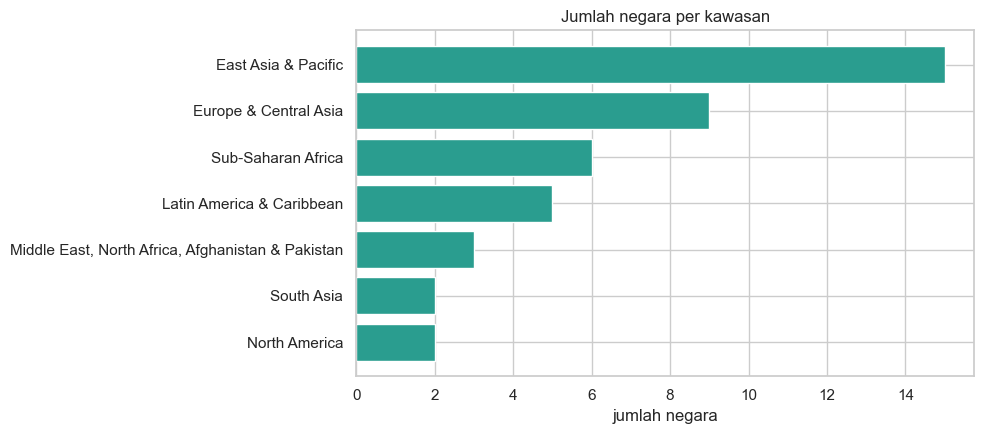

In [22]:
# 📊 EDA TABEL | dim_country | jumlah negara per kawasan

jml_reg = dim_c["region"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(jml_reg.index.astype(str), jml_reg.values, color="#2a9d8f")
ax.set(title="Jumlah negara per kawasan", xlabel="jumlah negara")
plt.tight_layout(); plt.show()

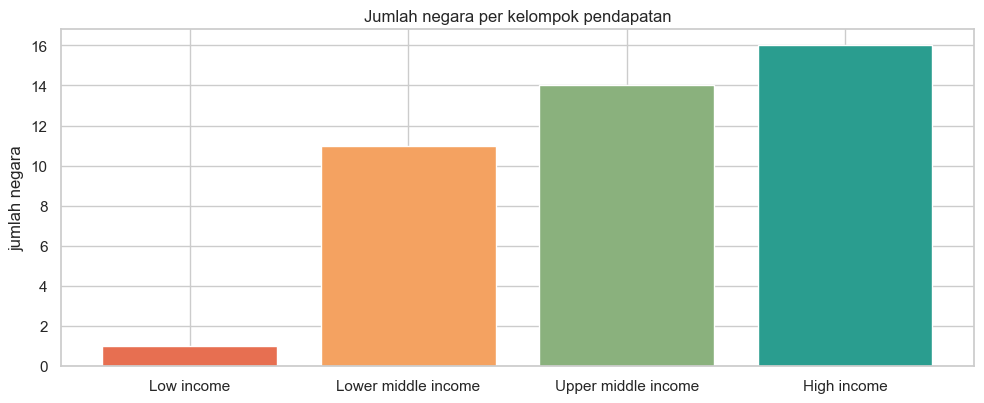

In [23]:
# 📊 EDA TABEL | dim_country | jumlah negara per kelompok pendapatan

urut_inc = [u for u in URUT_INCOME if u in set(dim_c["income_level"].dropna())] or sorted(dim_c["income_level"].dropna().unique())
jml_inc = dim_c["income_level"].value_counts().reindex(urut_inc).fillna(0)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(jml_inc.index.astype(str), jml_inc.values, color=["#e76f51", "#f4a261", "#8ab17d", "#2a9d8f"][:len(jml_inc)])
ax.set(title="Jumlah negara per kelompok pendapatan", ylabel="jumlah negara")
plt.tight_layout(); plt.show()

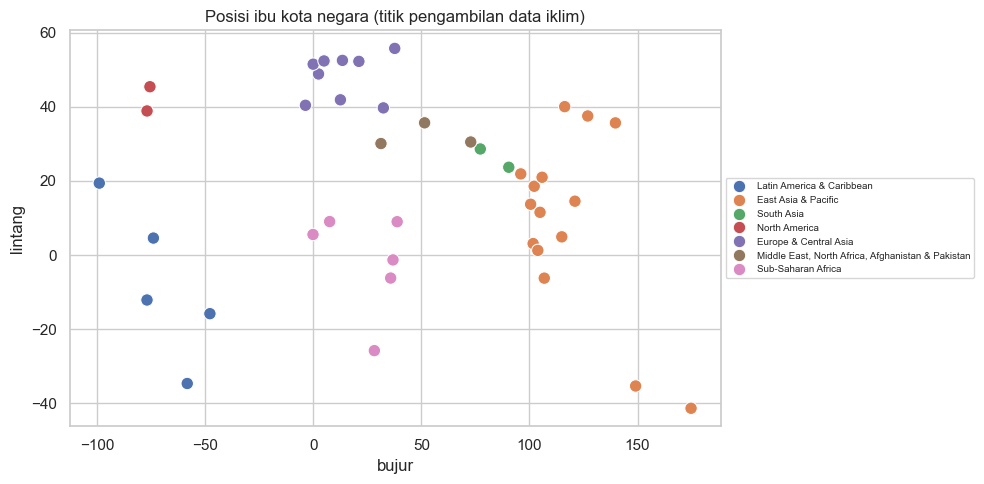

In [24]:
# 📊 EDA TABEL | dim_country | posisi ibu kota (titik pengambilan data iklim)

fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=dim_c.dropna(subset=["capital_lat", "capital_lon"]), x="capital_lon", y="capital_lat", hue="region", s=80, ax=ax)
ax.set(title="Posisi ibu kota negara (titik pengambilan data iklim)", xlabel="bujur", ylabel="lintang")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.show()

In [25]:
# 💡 TEMUAN | dim_country | kesimpulan EDA tabel

catat(f"**Temuan EDA tabel.** Data mencakup **{len(dim_c)} negara** di **{dim_c['region'].nunique()} kawasan**; kawasan terbanyak: "
      f"**{jml_reg.index[-1]}** ({int(jml_reg.iloc[-1])} negara). Sebaran kelompok pendapatan: " +
      "; ".join(f"{k} = {int(v)}" for k, v in jml_inc.items()) + ". "
      "Karena iklim diambil di koordinat ibu kota, nilainya hanya mewakili iklim negara secara kasar.")

**Temuan EDA tabel.** Data mencakup **42 negara** di **7 kawasan**; kawasan terbanyak: **East Asia & Pacific** (15 negara). Sebaran kelompok pendapatan: Low income = 1; Lower middle income = 11; Upper middle income = 14; High income = 16. Karena iklim diambil di koordinat ibu kota, nilainya hanya mewakili iklim negara secara kasar.

## 4. Tabel `fact_agriculture` (data utama)
Satu baris = satu negara pada satu tahun. Berisi hasil serealia (kg/ha), pupuk, lahan arable, nilai tambah dan tenaga kerja pertanian.

### 4.1 🔍 Assessing

In [26]:
# 🔍 ASSESSING | fact_agriculture | info(): tipe data dan kelengkapan

print(f"Ukuran: {fact_agriculture.shape[0]:,} baris x {fact_agriculture.shape[1]} kolom\n")
fact_agriculture.info()

Ukuran: 1,050 baris x 9 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   agriculture_id        1050 non-null   int64         
 1   country_id            1050 non-null   int64         
 2   year                  1050 non-null   int64         
 3   cereal_yield_kg_ha    1025 non-null   float64       
 4   fertilizer_kg_ha      1046 non-null   float64       
 5   arable_land_pct       1050 non-null   float64       
 6   agri_value_added_pct  1044 non-null   float64       
 7   agri_employment_pct   1050 non-null   float64       
 8   loaded_at             1050 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(5), int64(3)
memory usage: 74.0 KB


In [27]:
# 🔍 ASSESSING | fact_agriculture | describe(): statistik kolom numerik

display(fact_agriculture.drop(columns=["agriculture_id", "loaded_at"]).describe().T)

,count,mean,std,min,25%,50%,75%,max
country_id,"1,050.00",21.50,12.13,1.00,11.00,21.50,32.00,42.00
year,"1,050.00","2,012.00",7.21,"2,000.00","2,006.00","2,012.00","2,018.00","2,024.00"
cereal_yield_kg_ha,"1,025.00","4,129.08","1,949.61",744.30,"2,680.90","3,678.30","5,462.00","9,101.90"
fertilizer_kg_ha,"1,046.00",261.61,477.53,0.00,59.84,134.58,253.96,"5,617.46"
arable_land_pct,"1,050.00",17.87,14.39,0.76,6.51,14.17,25.59,64.33
agri_value_added_pct,"1,044.00",10.42,10.43,0.03,2.11,6.89,16.34,57.24
agri_employment_pct,"1,050.00",24.12,22.53,0.08,4.12,15.42,41.98,86.85


In [28]:
# 🔍 ASSESSING | fact_agriculture | nilai kosong (null) per kolom

display(tabel_null(fact_agriculture))

,jumlah_null,persen_null
agriculture_id,0,0.00
country_id,0,0.00
year,0,0.00
cereal_yield_kg_ha,25,2.40
fertilizer_kg_ha,4,0.40
arable_land_pct,0,0.00
agri_value_added_pct,6,0.60
agri_employment_pct,0,0.00
loaded_at,0,0.00


In [29]:
# 🔍 ASSESSING | fact_agriculture | duplikat

cek_duplikat(fact_agriculture, KUNCI)

Baris identik (semua kolom sama)   : 0
Duplikat pada kunci ['country_id', 'year'] : 0


(0, 0)

In [30]:
# 🔍 ASSESSING | fact_agriculture | nilai tidak valid (di luar aturan)

cek_invalid(fact_agriculture, RULES_AGRI)

,kolom,batas_min,batas_maks,jumlah_tidak_valid
0,cereal_yield_kg_ha,0,NaN,0
1,fertilizer_kg_ha,0,NaN,0
2,arable_land_pct,0,100.00,0
3,agri_value_added_pct,0,100.00,0
4,agri_employment_pct,0,100.00,0


Total nilai tidak valid: 0


In [31]:
# 🔍 ASSESSING | fact_agriculture | ringkasan assessing tabel ini

sebelum.append(ringkas(fact_agriculture, "fact_agriculture", KUNCI, RULES_AGRI))
display(pd.DataFrame([sebelum[-1]]).set_index("tabel"))

,baris,total_null,duplikat_baris,duplikat_kunci,nilai_tidak_valid
tabel,,,,,
fact_agriculture,1050,35,0,0,0


**Pola nilai kosong.** Total kosong belum cukup. Peta di bawah menunjukkan *di mana* kosongnya: acak, menumpuk pada tahun tertentu, atau seluruh negara.

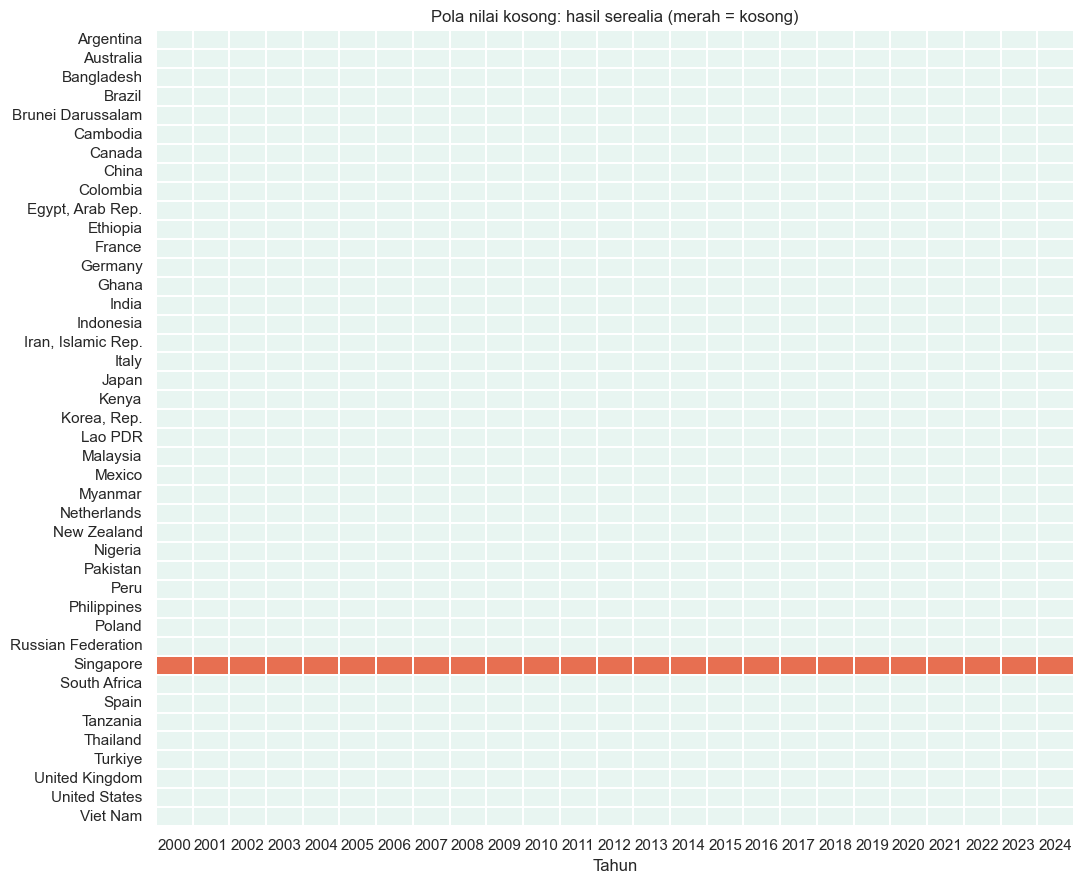

In [32]:
# 🔍 ASSESSING | fact_agriculture | peta nilai kosong: hasil serealia (negara × tahun)

m_y = peta_kosong(fact_agriculture, "cereal_yield_kg_ha", "hasil serealia")

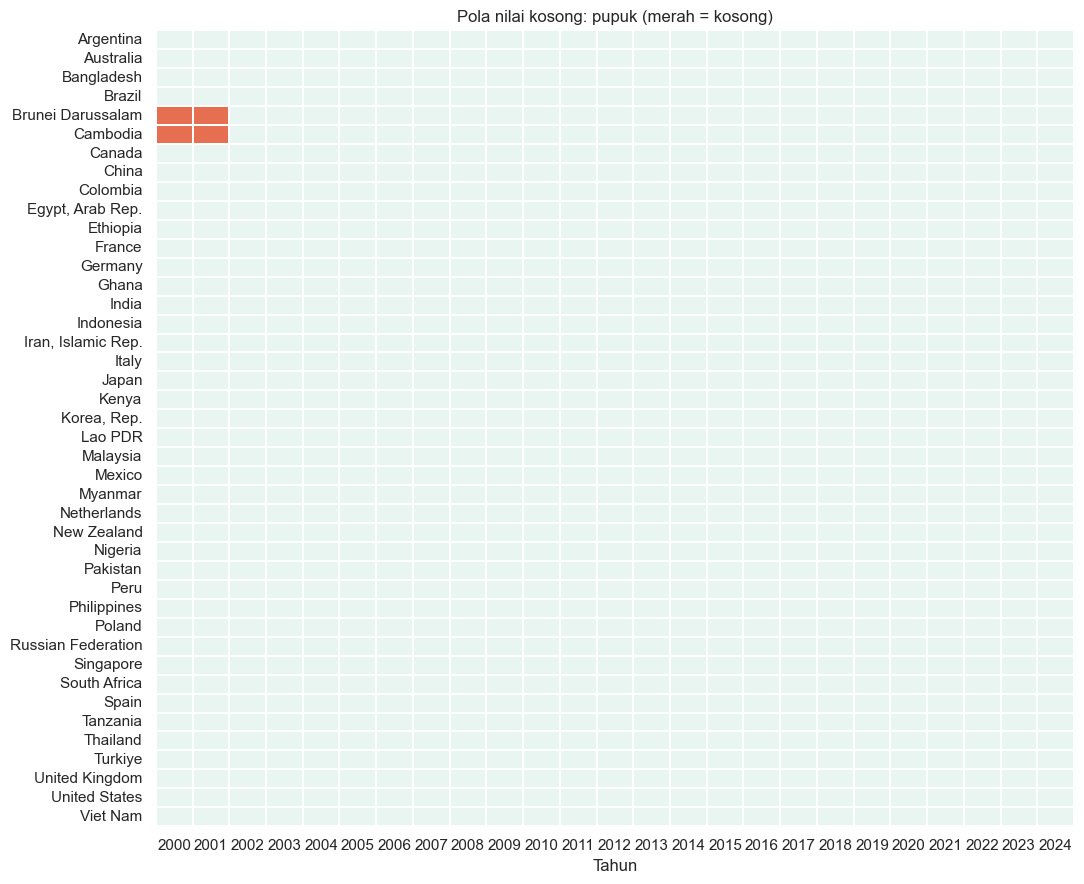

In [33]:
# 🔍 ASSESSING | fact_agriculture | peta nilai kosong: pupuk (negara × tahun)

m_f = peta_kosong(fact_agriculture, "fertilizer_kg_ha", "pupuk")

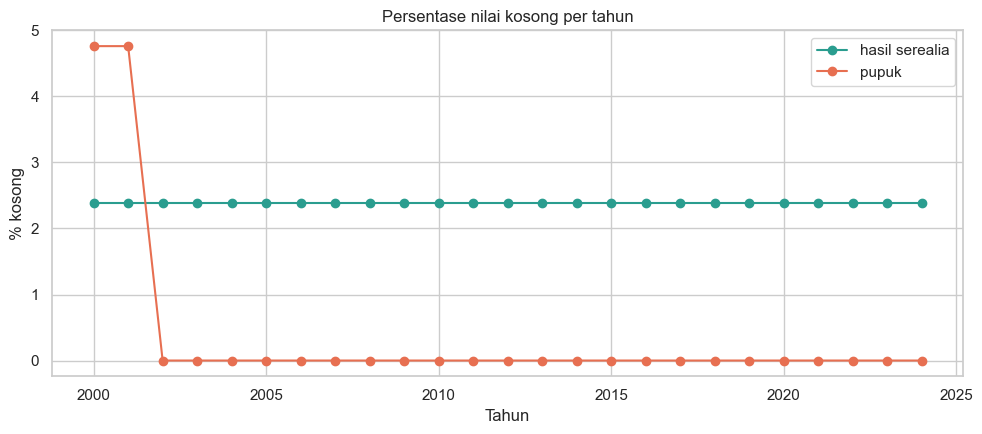

In [34]:
# 🔍 ASSESSING | fact_agriculture | persentase nilai kosong per tahun

per_tahun = pd.DataFrame({
    "hasil serealia": fact_agriculture.groupby("year")["cereal_yield_kg_ha"].apply(lambda s: s.isna().mean() * 100),
    "pupuk": fact_agriculture.groupby("year")["fertilizer_kg_ha"].apply(lambda s: s.isna().mean() * 100)})
fig, ax = plt.subplots(figsize=(10, 4.5))
per_tahun.plot(ax=ax, marker="o", color=["#2a9d8f", "#e76f51"])
ax.set(title="Persentase nilai kosong per tahun", xlabel="Tahun", ylabel="% kosong")
plt.tight_layout(); plt.show()

In [35]:
# 💡 TEMUAN | fact_agriculture | kesimpulan assessing

na = fact_agriculture[list(RULES_AGRI)].isna().mean().sort_values(ascending=False) * 100
penuh = m_y.index[(m_y == 1).all(axis=1)].tolist()
th = per_tahun["hasil serealia"].idxmax()
rata = per_tahun["hasil serealia"].mean()
menumpuk = per_tahun["hasil serealia"].max() >= max(20, 2 * rata)     # tahun terburuk jauh di atas rata-rata
teks = (f"**Temuan assessing.** Kolom dengan nilai kosong terbanyak adalah `{na.index[0]}` ({na.iloc[0]:.1f}%). "
        f"Kekosongan hasil serealia paling tinggi pada tahun **{int(th)}** ({per_tahun['hasil serealia'].max():.0f}% negara; rata-rata semua tahun {rata:.0f}%), ")
teks += ("jadi kosongnya **menumpuk pada tahun tertentu**, bukan acak. " if menumpuk
         else "dan tidak jauh di atas tahun lain, jadi kosongnya **relatif tersebar** antartahun. ")
if penuh:
    teks += f"Negara yang hasil serealianya kosong di **semua tahun**: **{', '.join(penuh)}** (kosong struktural, mungkin karena negara itu memang tidak punya data serealia). "
teks += ("Nilai kosong pada data World Bank berarti tidak dilaporkan, bukan nol, sehingga **tidak boleh** diisi 0. "
         "Duplikat pada kunci (negara, tahun) seharusnya nol karena dijaga *unique key* di MySQL.")
catat(teks)

**Temuan assessing.** Kolom dengan nilai kosong terbanyak adalah `cereal_yield_kg_ha` (2.4%). Kekosongan hasil serealia paling tinggi pada tahun **2000** (2% negara; rata-rata semua tahun 2%), dan tidak jauh di atas tahun lain, jadi kosongnya **relatif tersebar** antartahun. Negara yang hasil serealianya kosong di **semua tahun**: **Singapore** (kosong struktural, mungkin karena negara itu memang tidak punya data serealia). Nilai kosong pada data World Bank berarti tidak dilaporkan, bukan nol, sehingga **tidak boleh** diisi 0. Duplikat pada kunci (negara, tahun) seharusnya nol karena dijaga *unique key* di MySQL.

### 4.2 🧹 Cleaning
| Masalah | Keputusan | Alasan |
|---|---|---|
| Kolom teknis (`agriculture_id`, `loaded_at`) | Dibuang | Tidak dipakai dalam analisis |
| Duplikat pada (negara, tahun) | Dihapus, simpan yang terakhir | Satu negara-tahun hanya satu baris |
| Nilai di luar aturan validitas | Diubah menjadi kosong (NaN) | Baris masih punya indikator lain yang valid |
| Baris yang seluruh indikatornya kosong | Dihapus | Tidak membawa informasi |
| Celah pendek (≤ 2 tahun) pada lahan arable, nilai tambah, tenaga kerja | Interpolasi linear dalam satu negara | Indikator ini berubah bertahap |
| Kosong pada hasil serealia dan pupuk | **Tidak** diisi | Variabel inti; mengisinya berarti mengarang data |
| Outlier hasil serealia | Ditandai (`outlier_yield`), **tidak** dihapus | Hasil sangat tinggi mungkin memang nyata |

In [36]:
# 🧹 CLEANING | fact_agriculture | langkah 1: buang kolom teknis dan samakan tipe data

agri_c = fact_agriculture.drop(columns=["agriculture_id", "loaded_at"]).copy()
agri_c["year"] = agri_c["year"].astype(int)
for c in RULES_AGRI:
    agri_c[c] = pd.to_numeric(agri_c[c], errors="coerce")
log_a = {"tabel": "fact_agriculture", "baris_awal": len(fact_agriculture)}
print("Kolom setelah dibersihkan:", list(agri_c.columns))

Kolom setelah dibersihkan: ['country_id', 'year', 'cereal_yield_kg_ha', 'fertilizer_kg_ha', 'arable_land_pct', 'agri_value_added_pct', 'agri_employment_pct']


In [37]:
# 🧹 CLEANING | fact_agriculture | langkah 2: hapus duplikat (negara, tahun)

n0 = len(agri_c)
agri_c = agri_c.drop_duplicates(subset=KUNCI, keep="last")
log_a["duplikat_dihapus"] = n0 - len(agri_c)
print(f"Duplikat dihapus: {log_a['duplikat_dihapus']} baris ({n0:,} -> {len(agri_c):,})")

Duplikat dihapus: 0 baris (1,050 -> 1,050)


In [38]:
# 🧹 CLEANING | fact_agriculture | langkah 3: nilai tidak valid diubah menjadi kosong (NaN)

log_a["nilai_tidak_valid_jadi_NaN"] = ubah_invalid(agri_c, RULES_AGRI)
print(f"Nilai tidak valid diubah menjadi NaN: {log_a['nilai_tidak_valid_jadi_NaN']}")

Nilai tidak valid diubah menjadi NaN: 0


In [39]:
# 🧹 CLEANING | fact_agriculture | langkah 4: hapus baris yang seluruh indikatornya kosong

kosong = agri_c[list(RULES_AGRI)].isna().all(axis=1)
log_a["baris_semua_kosong_dihapus"] = int(kosong.sum())
agri_c = agri_c[~kosong].reset_index(drop=True)
print(f"Baris kosong total dihapus: {log_a['baris_semua_kosong_dihapus']}")

Baris kosong total dihapus: 0


In [40]:
# 🧹 CLEANING | fact_agriculture | langkah 5: interpolasi celah pendek (≤ 2 tahun) untuk indikator yang berubah lambat

LAMBAT = ["arable_land_pct", "agri_value_added_pct", "agri_employment_pct"]
agri_c = agri_c.sort_values(["country_id", "year"]).reset_index(drop=True)
kosong_awal = agri_c[LAMBAT].isna().sum()
agri_c[LAMBAT] = agri_c.groupby("country_id")[LAMBAT].transform(
    lambda s: s.interpolate(method="linear", limit=2, limit_area="inside"))
terisi = kosong_awal - agri_c[LAMBAT].isna().sum()
print("Nilai terisi lewat interpolasi:"); print(terisi.to_string())

Nilai terisi lewat interpolasi:
arable_land_pct         0
agri_value_added_pct    0
agri_employment_pct     0


In [41]:
# 🧹 CLEANING | fact_agriculture | langkah 6: tandai outlier hasil serealia (tidak dihapus)

q1_, q3_ = agri_c["cereal_yield_kg_ha"].quantile([.25, .75])
batas_atas = q3_ + 1.5 * (q3_ - q1_)
agri_c["outlier_yield"] = agri_c["cereal_yield_kg_ha"] > batas_atas
print(f"Batas outlier atas (aturan IQR): {batas_atas:,.0f} kg/ha -> {int(agri_c['outlier_yield'].sum())} baris ditandai")
print(agri_c.loc[agri_c["outlier_yield"], "country_id"].map(dim_country.set_index("country_id")["country_name"]).value_counts().head(5).to_string())

Batas outlier atas (aturan IQR): 9,634 kg/ha -> 0 baris ditandai
Series([], )


In [42]:
# 🧹 CLEANING | fact_agriculture | ringkasan hasil cleaning

log_a["baris_akhir"] = len(agri_c)
logs.append(log_a)
display(pd.DataFrame([log_a]).set_index("tabel"))

,baris_awal,duplikat_dihapus,nilai_tidak_valid_jadi_NaN,baris_semua_kosong_dihapus,baris_akhir
tabel,,,,,
fact_agriculture,1050,0,0,0,1050


### 4.3 ✅ Assessing ulang

In [43]:
# ✅ ASSESSING ULANG | fact_agriculture | info(): tipe data dan kelengkapan

print(f"Ukuran: {agri_c.shape[0]:,} baris x {agri_c.shape[1]} kolom\n")
agri_c.info()

Ukuran: 1,050 baris x 8 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   country_id            1050 non-null   int64  
 1   year                  1050 non-null   int64  
 2   cereal_yield_kg_ha    1025 non-null   float64
 3   fertilizer_kg_ha      1046 non-null   float64
 4   arable_land_pct       1050 non-null   float64
 5   agri_value_added_pct  1044 non-null   float64
 6   agri_employment_pct   1050 non-null   float64
 7   outlier_yield         1050 non-null   bool   
dtypes: bool(1), float64(5), int64(2)
memory usage: 58.6 KB


In [44]:
# ✅ ASSESSING ULANG | fact_agriculture | describe(): statistik kolom numerik

display(agri_c.describe().T)

,count,mean,std,min,25%,50%,75%,max
country_id,"1,050.00",21.50,12.13,1.00,11.00,21.50,32.00,42.00
year,"1,050.00","2,012.00",7.21,"2,000.00","2,006.00","2,012.00","2,018.00","2,024.00"
cereal_yield_kg_ha,"1,025.00","4,129.08","1,949.61",744.30,"2,680.90","3,678.30","5,462.00","9,101.90"
fertilizer_kg_ha,"1,046.00",261.61,477.53,0.00,59.84,134.58,253.96,"5,617.46"
arable_land_pct,"1,050.00",17.87,14.39,0.76,6.51,14.17,25.59,64.33
agri_value_added_pct,"1,044.00",10.42,10.43,0.03,2.11,6.89,16.34,57.24
agri_employment_pct,"1,050.00",24.12,22.53,0.08,4.12,15.42,41.98,86.85


In [45]:
# ✅ ASSESSING ULANG | fact_agriculture | nilai kosong per kolom: sebelum vs sesudah

display(bandingkan_null(fact_agriculture, agri_c))

,% kosong sebelum,% kosong sesudah
country_id,0.00,0.00
year,0.00,0.00
cereal_yield_kg_ha,2.40,2.40
fertilizer_kg_ha,0.40,0.40
arable_land_pct,0.00,0.00
agri_value_added_pct,0.60,0.60
agri_employment_pct,0.00,0.00
outlier_yield,NaN,0.00


In [46]:
# ✅ ASSESSING ULANG | fact_agriculture | ringkasan: sebelum vs sesudah

sesudah.append(ringkas(agri_c, "fact_agriculture", KUNCI, RULES_AGRI))
bandingkan("fact_agriculture")

,baris,total_null,duplikat_baris,duplikat_kunci,nilai_tidak_valid
sebelum,1050,35,0,0,0
sesudah,1050,35,0,0,0


In [47]:
# 💡 TEMUAN | fact_agriculture | kesimpulan assessing ulang

temuan_ulang("fact_agriculture")

**Temuan assessing ulang (fact_agriculture).** Nilai tidak valid: 0 → 0; duplikat kunci: 0 → 0; baris: 1,050 → 1,050; nilai kosong: 35 → 35. Nilai kosong sengaja **tidak** ditutup dengan angka karangan; yang berubah adalah kita tahu persis di mana kosongnya.

### 4.4 📊 EDA tabel `fact_agriculture`
**Tujuan:** mengenal sebaran tiap indikator pertanian sebelum digabung. **Visual:** histogram untuk bentuk sebaran, boxplot untuk membandingkan beberapa persentase pada skala sama, garis untuk perubahan waktu.

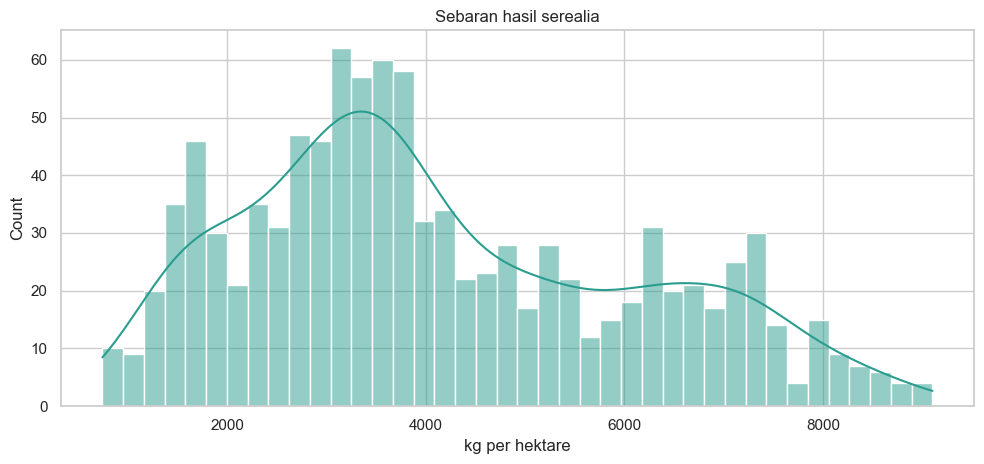

In [48]:
# 📊 EDA TABEL | fact_agriculture | sebaran hasil serealia

y_ = agri_c["cereal_yield_kg_ha"].dropna()
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(y_, bins=40, kde=True, color="#2a9d8f", ax=ax)
ax.set(title="Sebaran hasil serealia", xlabel="kg per hektare")
plt.tight_layout(); plt.show()

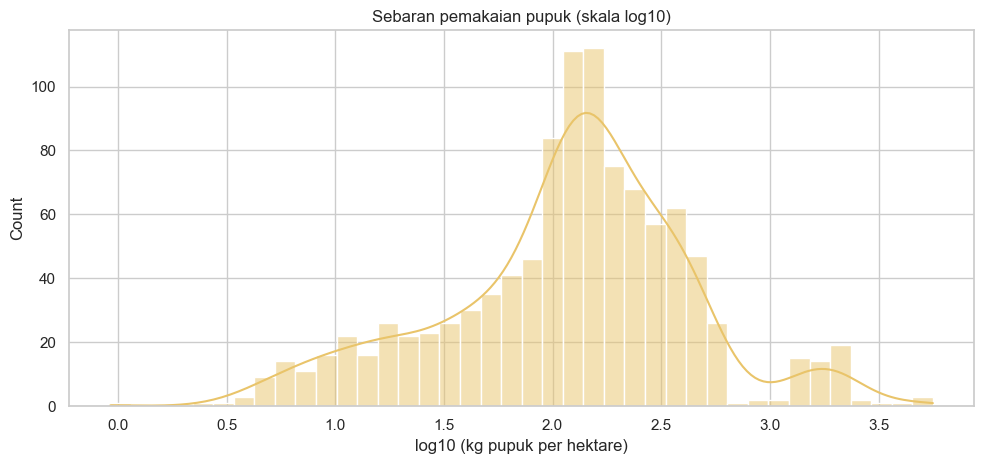

In [49]:
# 📊 EDA TABEL | fact_agriculture | sebaran pemakaian pupuk (skala log10)

f_ = agri_c["fertilizer_kg_ha"].dropna()
f_ = f_[f_ > 0]
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(np.log10(f_), bins=40, kde=True, color="#e9c46a", ax=ax)
ax.set(title="Sebaran pemakaian pupuk (skala log10)", xlabel="log10 (kg pupuk per hektare)")
plt.tight_layout(); plt.show()

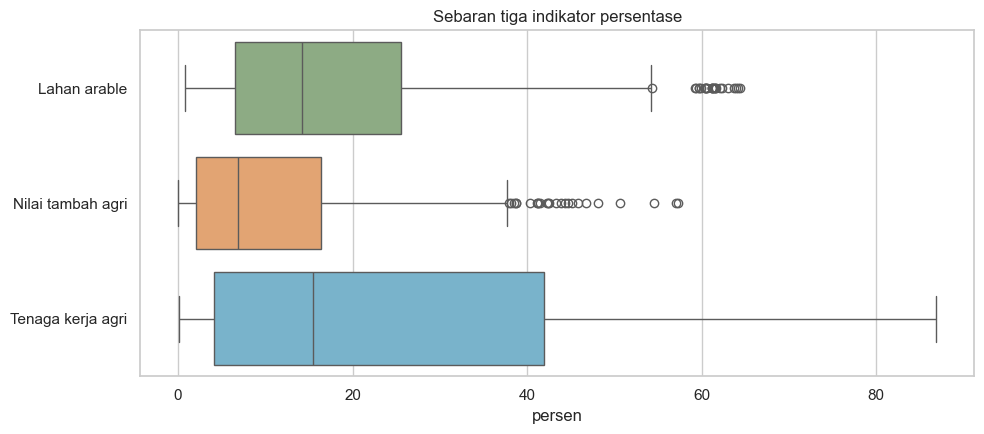

In [50]:
# 📊 EDA TABEL | fact_agriculture | sebaran tiga indikator persentase

persen = agri_c[LAMBAT].rename(columns={"arable_land_pct": "Lahan arable", "agri_value_added_pct": "Nilai tambah agri", "agri_employment_pct": "Tenaga kerja agri"})
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=persen, orient="h", palette=["#8ab17d", "#f4a261", "#6bb8d9"], ax=ax)
ax.set(title="Sebaran tiga indikator persentase", xlabel="persen")
plt.tight_layout(); plt.show()

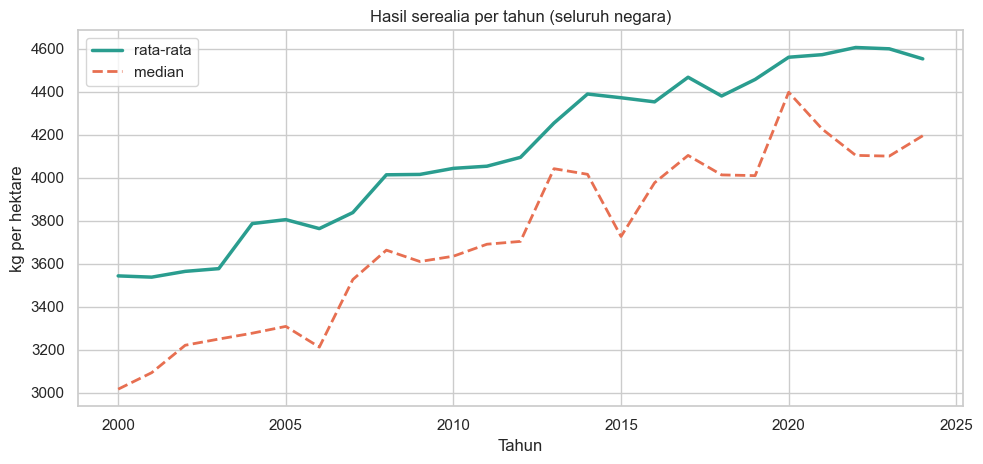

In [51]:
# 📊 EDA TABEL | fact_agriculture | hasil serealia per tahun

tren = agri_c.groupby("year")["cereal_yield_kg_ha"].agg(["mean", "median"])
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(tren.index, tren["mean"], color="#2a9d8f", lw=2.5, label="rata-rata")
ax.plot(tren.index, tren["median"], color="#e76f51", lw=2, ls="--", label="median")
ax.set(title="Hasil serealia per tahun (seluruh negara)", xlabel="Tahun", ylabel="kg per hektare"); ax.legend()
plt.tight_layout(); plt.show()

In [52]:
# 💡 TEMUAN | fact_agriculture | kesimpulan EDA tabel

arah = "miring ke kanan (sebagian kecil negara berhasil sangat tinggi)" if y_.skew() > .5 else "relatif simetris"
catat(f"**Temuan EDA tabel.** Hasil serealia rata-rata {y_.mean():,.0f} kg/ha, median {y_.median():,.0f} kg/ha; sebarannya {arah}. "
      f"Dari tahun {int(tren.index.min())} ke {int(tren.index.max())}, rata-rata berubah {((tren['mean'].iloc[-1] / tren['mean'].iloc[0]) - 1) * 100:+.0f}%. "
      "Pupuk sangat miring sehingga dipakai skala log pada analisis berikutnya.")

**Temuan EDA tabel.** Hasil serealia rata-rata 4,129 kg/ha, median 3,678 kg/ha; sebarannya miring ke kanan (sebagian kecil negara berhasil sangat tinggi). Dari tahun 2000 ke 2024, rata-rata berubah +28%. Pupuk sangat miring sehingga dipakai skala log pada analisis berikutnya.

## 5. Tabel `fact_economic`
Satu baris = satu negara pada satu tahun. Berisi GDP per kapita dan populasi.

### 5.1 🔍 Assessing

In [53]:
# 🔍 ASSESSING | fact_economic | info(): tipe data dan kelengkapan

print(f"Ukuran: {fact_economic.shape[0]:,} baris x {fact_economic.shape[1]} kolom\n")
fact_economic.info()

Ukuran: 1,050 baris x 6 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   economic_id         1050 non-null   int64         
 1   country_id          1050 non-null   int64         
 2   year                1050 non-null   int64         
 3   gdp_per_capita_usd  1050 non-null   float64       
 4   population          1050 non-null   int64         
 5   loaded_at           1050 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(4)
memory usage: 49.3 KB


In [54]:
# 🔍 ASSESSING | fact_economic | describe(): statistik kolom numerik

display(fact_economic.drop(columns=["economic_id", "loaded_at"]).describe().T)

,count,mean,std,min,25%,50%,75%,max
country_id,"1,050.00",21.50,12.13,1.00,11.00,21.50,32.00,42.00
year,"1,050.00","2,012.00",7.21,"2,000.00","2,006.00","2,012.00","2,018.00","2,024.00"
gdp_per_capita_usd,"1,050.00","16,408.68","18,966.96",109.59,"1,932.83","6,917.19","30,823.92","94,896.56"
population,"1,050.00","137,862,740.27","272,063,133.97","326,424.00","34,361,269.25","61,147,630.50","121,872,017.50","1,450,935,791.00"


In [55]:
# 🔍 ASSESSING | fact_economic | nilai kosong (null) per kolom

display(tabel_null(fact_economic))

,jumlah_null,persen_null
economic_id,0,0.00
country_id,0,0.00
year,0,0.00
gdp_per_capita_usd,0,0.00
population,0,0.00
loaded_at,0,0.00


In [56]:
# 🔍 ASSESSING | fact_economic | duplikat

cek_duplikat(fact_economic, KUNCI)

Baris identik (semua kolom sama)   : 0
Duplikat pada kunci ['country_id', 'year'] : 0


(0, 0)

In [57]:
# 🔍 ASSESSING | fact_economic | nilai tidak valid (di luar aturan)

cek_invalid(fact_economic, RULES_ECON)

,kolom,batas_min,batas_maks,jumlah_tidak_valid
0,gdp_per_capita_usd,1,None,0
1,population,1,None,0


Total nilai tidak valid: 0


In [58]:
# 🔍 ASSESSING | fact_economic | ringkasan assessing tabel ini

sebelum.append(ringkas(fact_economic, "fact_economic", KUNCI, RULES_ECON))
display(pd.DataFrame([sebelum[-1]]).set_index("tabel"))

,baris,total_null,duplikat_baris,duplikat_kunci,nilai_tidak_valid
tabel,,,,,
fact_economic,1050,0,0,0,0


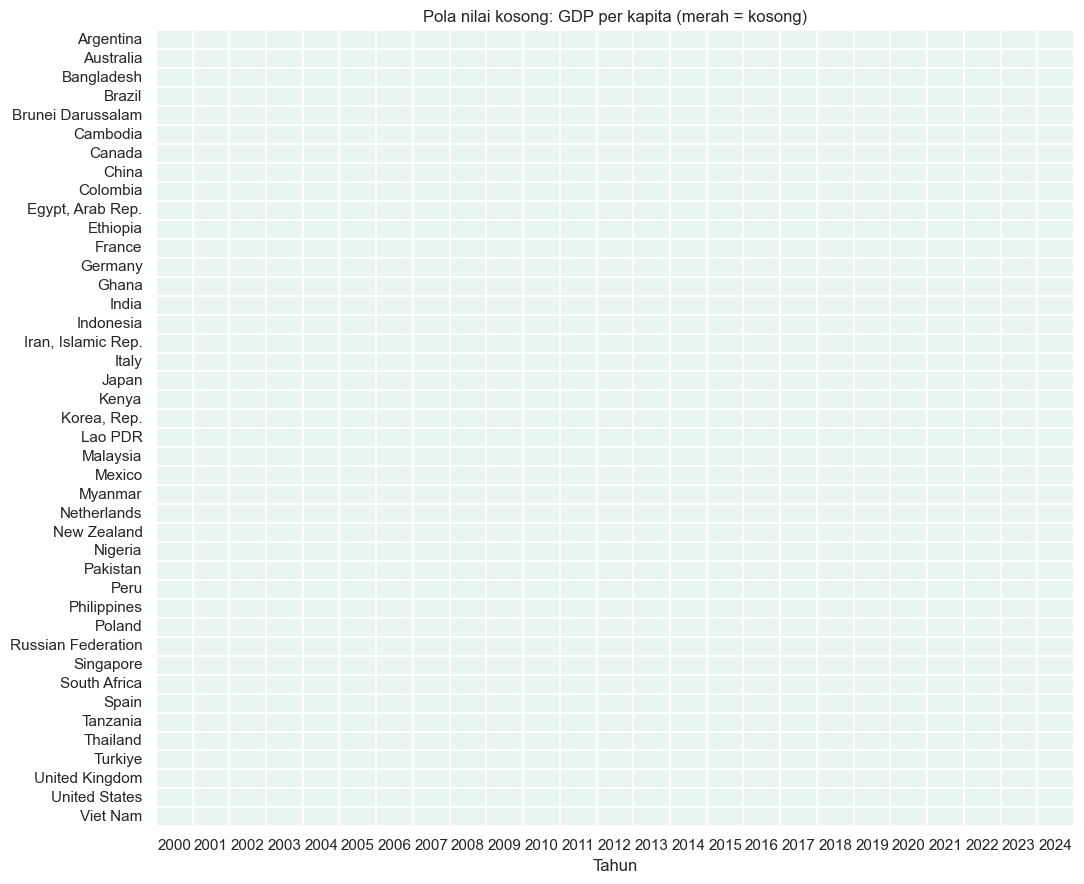

In [59]:
# 🔍 ASSESSING | fact_economic | peta nilai kosong: GDP per kapita (negara × tahun)

m_g = peta_kosong(fact_economic, "gdp_per_capita_usd", "GDP per kapita")

In [60]:
# 💡 TEMUAN | fact_economic | kesimpulan assessing

na_e = fact_economic[list(RULES_ECON)].isna().mean() * 100
catat(f"**Temuan assessing.** Nilai kosong GDP per kapita {na_e['gdp_per_capita_usd']:.1f}% dan populasi {na_e['population']:.1f}%. "
      "Perhatikan pada peta di atas apakah kosongnya berpola (negara atau tahun tertentu). Nilai kosong tidak diisi 0.")

**Temuan assessing.** Nilai kosong GDP per kapita 0.0% dan populasi 0.0%. Perhatikan pada peta di atas apakah kosongnya berpola (negara atau tahun tertentu). Nilai kosong tidak diisi 0.

### 5.2 🧹 Cleaning
| Masalah | Keputusan | Alasan |
|---|---|---|
| Kolom teknis (`economic_id`, `loaded_at`) | Dibuang | Tidak dipakai dalam analisis |
| Duplikat pada (negara, tahun) | Dihapus | Satu negara-tahun hanya satu baris |
| GDP atau populasi ≤ 0 | Diubah menjadi kosong | Tidak masuk akal |
| Baris yang seluruh indikatornya kosong | Dihapus | Tidak membawa informasi |
| Kosong pada GDP | **Tidak** diisi | Mengisi berarti mengarang data |
| Skala log GDP dan populasi | Dilakukan **setelah penggabungan** (bagian 7) | Sebaran sangat miring; transformasi adalah fitur turunan |

In [61]:
# 🧹 CLEANING | fact_economic | langkah 1: buang kolom teknis dan samakan tipe data

econ_c = fact_economic.drop(columns=["economic_id", "loaded_at"]).copy()
econ_c["year"] = econ_c["year"].astype(int)
for c in RULES_ECON:
    econ_c[c] = pd.to_numeric(econ_c[c], errors="coerce")
log_e = {"tabel": "fact_economic", "baris_awal": len(fact_economic)}
print("Kolom setelah dibersihkan:", list(econ_c.columns))

Kolom setelah dibersihkan: ['country_id', 'year', 'gdp_per_capita_usd', 'population']


In [62]:
# 🧹 CLEANING | fact_economic | langkah 2: hapus duplikat (negara, tahun)

n0 = len(econ_c)
econ_c = econ_c.drop_duplicates(subset=KUNCI, keep="last")
log_e["duplikat_dihapus"] = n0 - len(econ_c)
print(f"Duplikat dihapus: {log_e['duplikat_dihapus']} baris ({n0:,} -> {len(econ_c):,})")

Duplikat dihapus: 0 baris (1,050 -> 1,050)


In [63]:
# 🧹 CLEANING | fact_economic | langkah 3: nilai tidak valid diubah menjadi kosong (NaN)

log_e["nilai_tidak_valid_jadi_NaN"] = ubah_invalid(econ_c, RULES_ECON)
print(f"Nilai tidak valid diubah menjadi NaN: {log_e['nilai_tidak_valid_jadi_NaN']}")

Nilai tidak valid diubah menjadi NaN: 0


In [64]:
# 🧹 CLEANING | fact_economic | langkah 4: hapus baris yang seluruh indikatornya kosong

kosong = econ_c[list(RULES_ECON)].isna().all(axis=1)
log_e["baris_semua_kosong_dihapus"] = int(kosong.sum())
econ_c = econ_c[~kosong].reset_index(drop=True)
print(f"Baris kosong total dihapus: {log_e['baris_semua_kosong_dihapus']}")

Baris kosong total dihapus: 0


In [65]:
# 🧹 CLEANING | fact_economic | ringkasan hasil cleaning

log_e["baris_akhir"] = len(econ_c)
logs.append(log_e)
display(pd.DataFrame([log_e]).set_index("tabel"))

,baris_awal,duplikat_dihapus,nilai_tidak_valid_jadi_NaN,baris_semua_kosong_dihapus,baris_akhir
tabel,,,,,
fact_economic,1050,0,0,0,1050


### 5.3 ✅ Assessing ulang

In [66]:
# ✅ ASSESSING ULANG | fact_economic | info(): tipe data dan kelengkapan

print(f"Ukuran: {econ_c.shape[0]:,} baris x {econ_c.shape[1]} kolom\n")
econ_c.info()

Ukuran: 1,050 baris x 4 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   country_id          1050 non-null   int64  
 1   year                1050 non-null   int64  
 2   gdp_per_capita_usd  1050 non-null   float64
 3   population          1050 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 32.9 KB


In [67]:
# ✅ ASSESSING ULANG | fact_economic | describe(): statistik kolom numerik

display(econ_c.describe().T)

,count,mean,std,min,25%,50%,75%,max
country_id,"1,050.00",21.50,12.13,1.00,11.00,21.50,32.00,42.00
year,"1,050.00","2,012.00",7.21,"2,000.00","2,006.00","2,012.00","2,018.00","2,024.00"
gdp_per_capita_usd,"1,050.00","16,408.68","18,966.96",109.59,"1,932.83","6,917.19","30,823.92","94,896.56"
population,"1,050.00","137,862,740.27","272,063,133.97","326,424.00","34,361,269.25","61,147,630.50","121,872,017.50","1,450,935,791.00"


In [68]:
# ✅ ASSESSING ULANG | fact_economic | nilai kosong per kolom: sebelum vs sesudah

display(bandingkan_null(fact_economic, econ_c))

,% kosong sebelum,% kosong sesudah
country_id,0.00,0.00
year,0.00,0.00
gdp_per_capita_usd,0.00,0.00
population,0.00,0.00


In [69]:
# ✅ ASSESSING ULANG | fact_economic | ringkasan: sebelum vs sesudah

sesudah.append(ringkas(econ_c, "fact_economic", KUNCI, RULES_ECON))
bandingkan("fact_economic")

,baris,total_null,duplikat_baris,duplikat_kunci,nilai_tidak_valid
sebelum,1050,0,0,0,0
sesudah,1050,0,0,0,0


In [70]:
# 💡 TEMUAN | fact_economic | kesimpulan assessing ulang

temuan_ulang("fact_economic")

**Temuan assessing ulang (fact_economic).** Nilai tidak valid: 0 → 0; duplikat kunci: 0 → 0; baris: 1,050 → 1,050; nilai kosong: 0 → 0. Nilai kosong sengaja **tidak** ditutup dengan angka karangan; yang berubah adalah kita tahu persis di mana kosongnya.

### 5.4 📊 EDA tabel `fact_economic`
**Tujuan:** melihat sebaran GDP dan populasi, yang biasanya sangat miring. **Visual:** histogram skala log10 dan garis tren median.

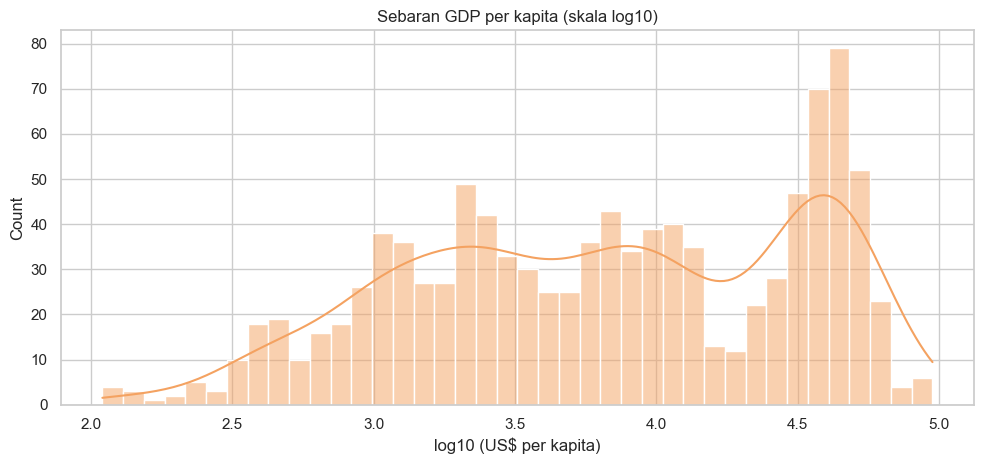

In [71]:
# 📊 EDA TABEL | fact_economic | sebaran GDP per kapita (skala log10)

g_ = econ_c["gdp_per_capita_usd"].dropna()
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(np.log10(g_), bins=40, kde=True, color="#f4a261", ax=ax)
ax.set(title="Sebaran GDP per kapita (skala log10)", xlabel="log10 (US$ per kapita)")
plt.tight_layout(); plt.show()

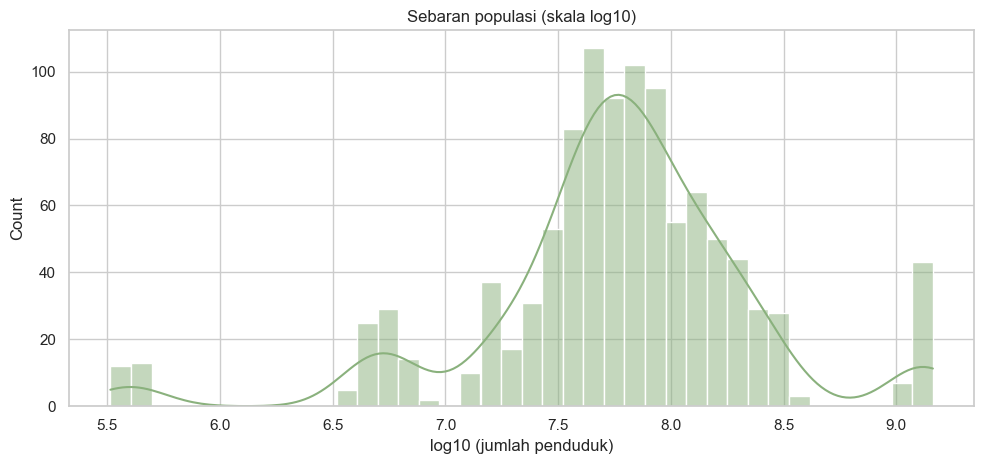

In [72]:
# 📊 EDA TABEL | fact_economic | sebaran populasi (skala log10)

p_ = econ_c["population"].dropna()
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(np.log10(p_), bins=40, kde=True, color="#8ab17d", ax=ax)
ax.set(title="Sebaran populasi (skala log10)", xlabel="log10 (jumlah penduduk)")
plt.tight_layout(); plt.show()

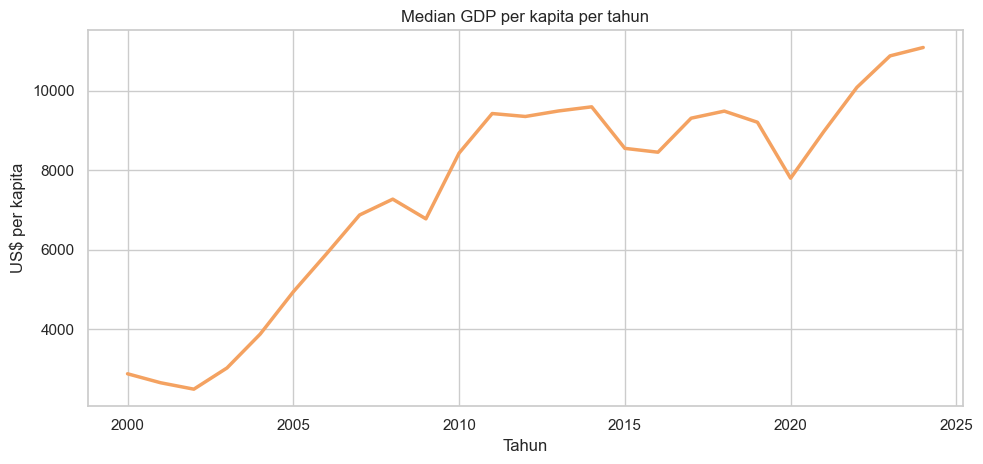

In [73]:
# 📊 EDA TABEL | fact_economic | median GDP per kapita per tahun

gm = econ_c.groupby("year")["gdp_per_capita_usd"].median()
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(gm.index, gm.values, color="#f4a261", lw=2.5)
ax.set(title="Median GDP per kapita per tahun", xlabel="Tahun", ylabel="US$ per kapita")
plt.tight_layout(); plt.show()

In [74]:
# 💡 TEMUAN | fact_economic | kesimpulan EDA tabel

catat(f"**Temuan EDA tabel.** Median GDP per kapita {g_.median():,.0f} US$, sedangkan rata-rata {g_.mean():,.0f} US$: rata-rata jauh di atas median, "
      "tanda sebaran yang miring ke kanan. Populasi juga sangat timpang (dari "
      f"{p_.min():,.0f} sampai {p_.max():,.0f} jiwa). Karena itu GDP dan populasi dipakai dalam skala log pada analisis dan model.")

**Temuan EDA tabel.** Median GDP per kapita 6,917 US$, sedangkan rata-rata 16,409 US$: rata-rata jauh di atas median, tanda sebaran yang miring ke kanan. Populasi juga sangat timpang (dari 326,424 sampai 1,450,935,791 jiwa). Karena itu GDP dan populasi dipakai dalam skala log pada analisis dan model.

## 6. Tabel `fact_climate` (data pendukung)
Satu baris = satu negara pada satu tahun. Berisi suhu dan curah hujan tahunan dari NASA POWER di koordinat ibu kota.

### 6.1 🔍 Assessing

In [75]:
# 🔍 ASSESSING | fact_climate | info(): tipe data dan kelengkapan

print(f"Ukuran: {fact_climate.shape[0]:,} baris x {fact_climate.shape[1]} kolom\n")
fact_climate.info()

Ukuran: 1,050 baris x 7 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   climate_id        1050 non-null   int64         
 1   country_id        1050 non-null   int64         
 2   year              1050 non-null   int64         
 3   avg_temp_c        1050 non-null   float64       
 4   total_precip_mm   1050 non-null   float64       
 5   months_with_data  1050 non-null   int64         
 6   loaded_at         1050 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(4)
memory usage: 57.6 KB


In [76]:
# 🔍 ASSESSING | fact_climate | describe(): statistik kolom numerik

display(fact_climate.drop(columns=["climate_id", "loaded_at"]).describe().T)

,count,mean,std,min,25%,50%,75%,max
country_id,"1,050.00",21.50,12.13,1.00,11.00,21.50,32.00,42.00
year,"1,050.00","2,012.00",7.21,"2,000.00","2,006.00","2,012.00","2,018.00","2,024.00"
avg_temp_c,"1,050.00",18.69,6.96,3.17,12.57,18.52,25.56,29.63
total_precip_mm,"1,050.00","1,105.02",812.00,7.30,584.91,877.20,"1,398.08","6,653.88"
months_with_data,"1,050.00",12.00,0.00,12.00,12.00,12.00,12.00,12.00


In [77]:
# 🔍 ASSESSING | fact_climate | nilai kosong (null) per kolom

display(tabel_null(fact_climate))

,jumlah_null,persen_null
climate_id,0,0.00
country_id,0,0.00
year,0,0.00
avg_temp_c,0,0.00
total_precip_mm,0,0.00
months_with_data,0,0.00
loaded_at,0,0.00


In [78]:
# 🔍 ASSESSING | fact_climate | duplikat

cek_duplikat(fact_climate, KUNCI)

Baris identik (semua kolom sama)   : 0
Duplikat pada kunci ['country_id', 'year'] : 0


(0, 0)

In [79]:
# 🔍 ASSESSING | fact_climate | nilai tidak valid (di luar aturan)

cek_invalid(fact_climate, RULES_CLIM)

,kolom,batas_min,batas_maks,jumlah_tidak_valid
0,avg_temp_c,-60,60,0
1,total_precip_mm,0,15000,0
2,months_with_data,0,12,0


Total nilai tidak valid: 0


In [80]:
# 🔍 ASSESSING | fact_climate | ringkasan assessing tabel ini

sebelum.append(ringkas(fact_climate, "fact_climate", KUNCI, RULES_CLIM))
display(pd.DataFrame([sebelum[-1]]).set_index("tabel"))

,baris,total_null,duplikat_baris,duplikat_kunci,nilai_tidak_valid
tabel,,,,,
fact_climate,1050,0,0,0,0


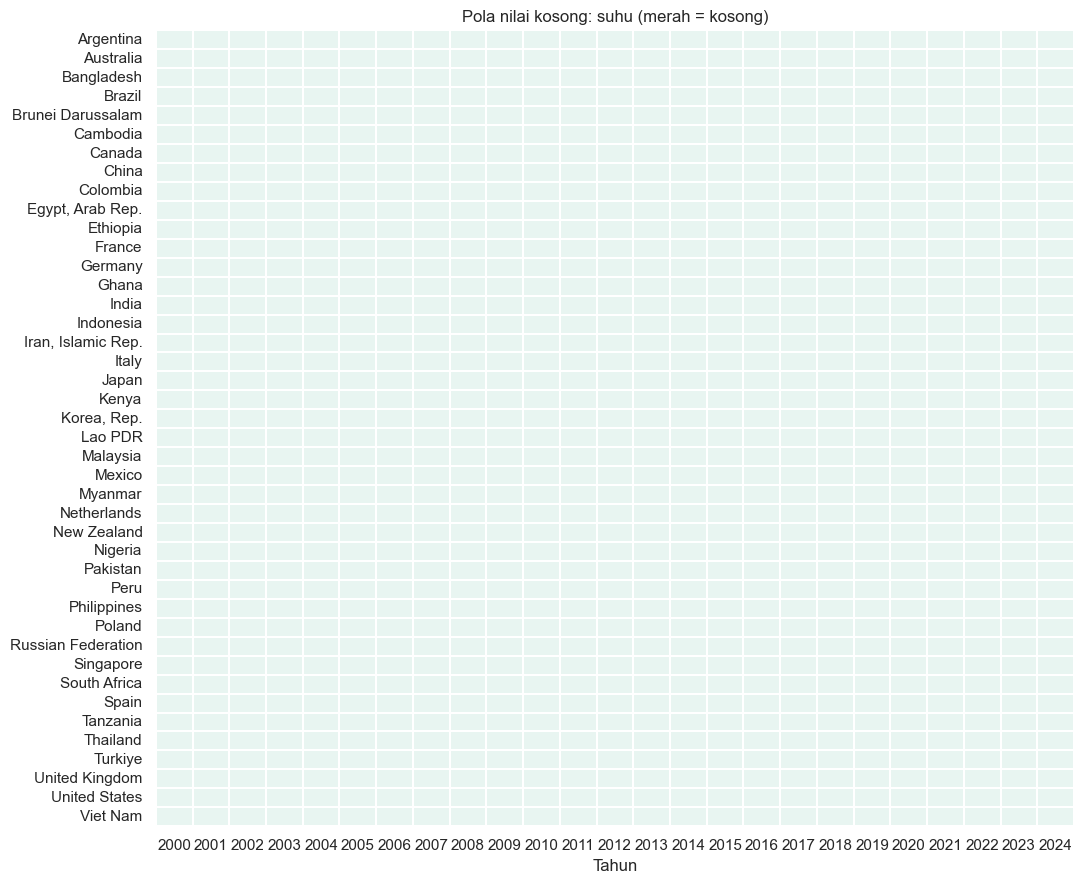

In [81]:
# 🔍 ASSESSING | fact_climate | peta nilai kosong: suhu (negara × tahun)

m_t = peta_kosong(fact_climate, "avg_temp_c", "suhu")

In [82]:
# 💡 TEMUAN | fact_climate | kesimpulan assessing

na_c = fact_climate[["avg_temp_c", "total_precip_mm"]].isna().mean() * 100
catat(f"**Temuan assessing.** Nilai kosong suhu {na_c['avg_temp_c']:.1f}% dan curah hujan {na_c['total_precip_mm']:.1f}%. "
      "Kolom `months_with_data` menunjukkan berapa bulan dalam setahun yang datanya valid; nilai di bawah 12 berarti tahun itu tidak lengkap.")

**Temuan assessing.** Nilai kosong suhu 0.0% dan curah hujan 0.0%. Kolom `months_with_data` menunjukkan berapa bulan dalam setahun yang datanya valid; nilai di bawah 12 berarti tahun itu tidak lengkap.

### 6.2 🧹 Cleaning
| Masalah | Keputusan | Alasan |
|---|---|---|
| Kolom teknis (`climate_id`, `loaded_at`) | Dibuang | Tidak dipakai dalam analisis |
| Duplikat pada (negara, tahun) | Dihapus | Satu negara-tahun hanya satu baris |
| Suhu di luar −60..60 °C, curah hujan negatif, bulan valid di luar 0..12 | Diubah menjadi kosong | Tidak masuk akal |
| Baris yang seluruh indikatornya kosong | Dihapus | Tidak membawa informasi |
| Kosong pada suhu atau curah hujan | **Tidak** diisi | Mengisi berarti mengarang data |

In [83]:
# 🧹 CLEANING | fact_climate | langkah 1: buang kolom teknis dan samakan tipe data

clim_c = fact_climate.drop(columns=["climate_id", "loaded_at"]).copy()
clim_c["year"] = clim_c["year"].astype(int)
for c in RULES_CLIM:
    clim_c[c] = pd.to_numeric(clim_c[c], errors="coerce")
log_c = {"tabel": "fact_climate", "baris_awal": len(fact_climate)}
print("Kolom setelah dibersihkan:", list(clim_c.columns))

Kolom setelah dibersihkan: ['country_id', 'year', 'avg_temp_c', 'total_precip_mm', 'months_with_data']


In [84]:
# 🧹 CLEANING | fact_climate | langkah 2: hapus duplikat (negara, tahun)

n0 = len(clim_c)
clim_c = clim_c.drop_duplicates(subset=KUNCI, keep="last")
log_c["duplikat_dihapus"] = n0 - len(clim_c)
print(f"Duplikat dihapus: {log_c['duplikat_dihapus']} baris ({n0:,} -> {len(clim_c):,})")

Duplikat dihapus: 0 baris (1,050 -> 1,050)


In [85]:
# 🧹 CLEANING | fact_climate | langkah 3: nilai tidak valid diubah menjadi kosong (NaN)

log_c["nilai_tidak_valid_jadi_NaN"] = ubah_invalid(clim_c, RULES_CLIM)
print(f"Nilai tidak valid diubah menjadi NaN: {log_c['nilai_tidak_valid_jadi_NaN']}")

Nilai tidak valid diubah menjadi NaN: 0


In [86]:
# 🧹 CLEANING | fact_climate | langkah 4: hapus baris yang seluruh indikatornya kosong

kosong = clim_c[list(RULES_CLIM)].isna().all(axis=1)
log_c["baris_semua_kosong_dihapus"] = int(kosong.sum())
clim_c = clim_c[~kosong].reset_index(drop=True)
print(f"Baris kosong total dihapus: {log_c['baris_semua_kosong_dihapus']}")

Baris kosong total dihapus: 0


In [87]:
# 🧹 CLEANING | fact_climate | ringkasan hasil cleaning

log_c["baris_akhir"] = len(clim_c)
logs.append(log_c)
display(pd.DataFrame([log_c]).set_index("tabel"))

,baris_awal,duplikat_dihapus,nilai_tidak_valid_jadi_NaN,baris_semua_kosong_dihapus,baris_akhir
tabel,,,,,
fact_climate,1050,0,0,0,1050


### 6.3 ✅ Assessing ulang

In [88]:
# ✅ ASSESSING ULANG | fact_climate | info(): tipe data dan kelengkapan

print(f"Ukuran: {clim_c.shape[0]:,} baris x {clim_c.shape[1]} kolom\n")
clim_c.info()

Ukuran: 1,050 baris x 5 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   country_id        1050 non-null   int64  
 1   year              1050 non-null   int64  
 2   avg_temp_c        1050 non-null   float64
 3   total_precip_mm   1050 non-null   float64
 4   months_with_data  1050 non-null   float64
dtypes: float64(3), int64(2)
memory usage: 41.1 KB


In [89]:
# ✅ ASSESSING ULANG | fact_climate | describe(): statistik kolom numerik

display(clim_c.describe().T)

,count,mean,std,min,25%,50%,75%,max
country_id,"1,050.00",21.50,12.13,1.00,11.00,21.50,32.00,42.00
year,"1,050.00","2,012.00",7.21,"2,000.00","2,006.00","2,012.00","2,018.00","2,024.00"
avg_temp_c,"1,050.00",18.69,6.96,3.17,12.57,18.52,25.56,29.63
total_precip_mm,"1,050.00","1,105.02",812.00,7.30,584.91,877.20,"1,398.08","6,653.88"
months_with_data,"1,050.00",12.00,0.00,12.00,12.00,12.00,12.00,12.00


In [90]:
# ✅ ASSESSING ULANG | fact_climate | nilai kosong per kolom: sebelum vs sesudah

display(bandingkan_null(fact_climate, clim_c))

,% kosong sebelum,% kosong sesudah
country_id,0.00,0.00
year,0.00,0.00
avg_temp_c,0.00,0.00
total_precip_mm,0.00,0.00
months_with_data,0.00,0.00


In [91]:
# ✅ ASSESSING ULANG | fact_climate | ringkasan: sebelum vs sesudah

sesudah.append(ringkas(clim_c, "fact_climate", KUNCI, RULES_CLIM))
bandingkan("fact_climate")

,baris,total_null,duplikat_baris,duplikat_kunci,nilai_tidak_valid
sebelum,1050,0,0,0,0
sesudah,1050,0,0,0,0


In [92]:
# 💡 TEMUAN | fact_climate | kesimpulan assessing ulang

temuan_ulang("fact_climate")

**Temuan assessing ulang (fact_climate).** Nilai tidak valid: 0 → 0; duplikat kunci: 0 → 0; baris: 1,050 → 1,050; nilai kosong: 0 → 0. Nilai kosong sengaja **tidak** ditutup dengan angka karangan; yang berubah adalah kita tahu persis di mana kosongnya.

### 6.4 📊 EDA tabel `fact_climate`
**Tujuan:** mengenal sebaran suhu dan curah hujan, hubungan keduanya antarnegara, dan apakah ada tren suhu. **Visual:** histogram, scatter (satu titik per negara), dan garis.

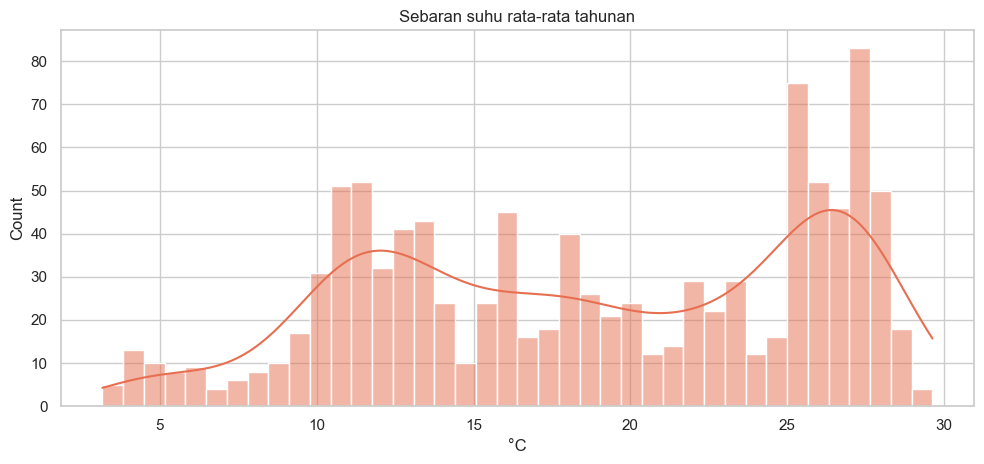

In [93]:
# 📊 EDA TABEL | fact_climate | sebaran suhu rata-rata tahunan

t_ = clim_c["avg_temp_c"].dropna()
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(t_, bins=40, kde=True, color="#e76f51", ax=ax)
ax.set(title="Sebaran suhu rata-rata tahunan", xlabel="°C")
plt.tight_layout(); plt.show()

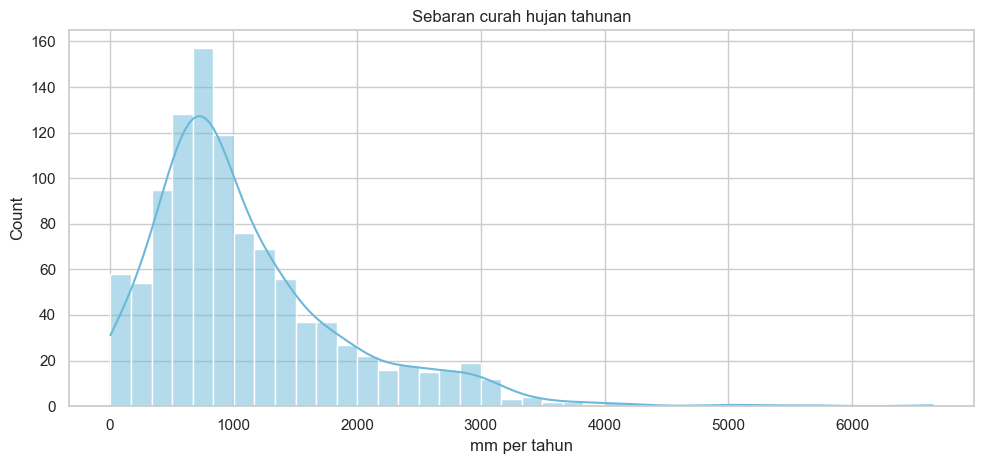

In [94]:
# 📊 EDA TABEL | fact_climate | sebaran curah hujan tahunan

pr_ = clim_c["total_precip_mm"].dropna()
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(pr_, bins=40, kde=True, color="#6bb8d9", ax=ax)
ax.set(title="Sebaran curah hujan tahunan", xlabel="mm per tahun")
plt.tight_layout(); plt.show()

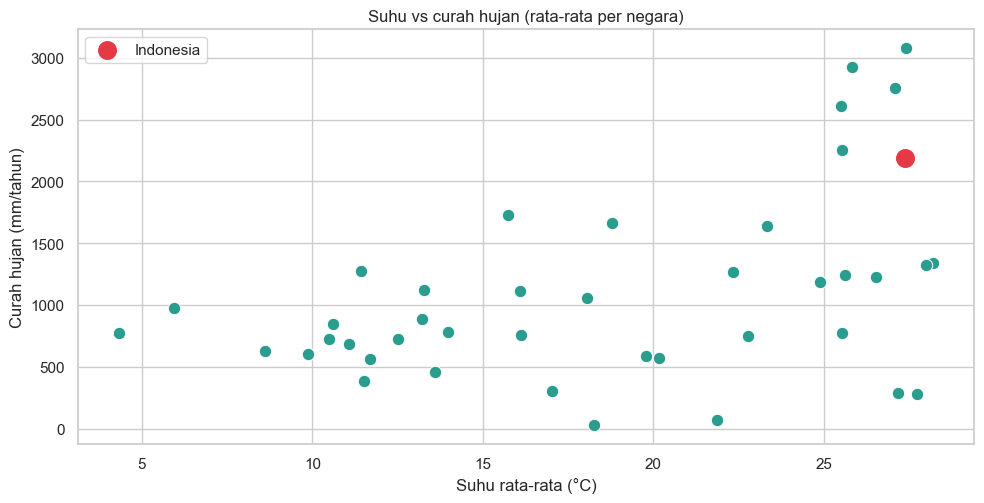

In [95]:
# 📊 EDA TABEL | fact_climate | suhu vs curah hujan (rata-rata per negara)

cm_ = (clim_c.groupby("country_id")[["avg_temp_c", "total_precip_mm"]].mean()
       .join(dim_c.set_index("country_id")[["country_code"]]))
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.scatterplot(data=cm_, x="avg_temp_c", y="total_precip_mm", color="#2a9d8f", s=80, ax=ax)
idn_ = cm_[cm_["country_code"] == "IDN"]
if not idn_.empty:
    ax.scatter(idn_["avg_temp_c"], idn_["total_precip_mm"], color="#e63946", s=160, zorder=3, label="Indonesia"); ax.legend()
ax.set(title="Suhu vs curah hujan (rata-rata per negara)", xlabel="Suhu rata-rata (°C)", ylabel="Curah hujan (mm/tahun)")
plt.tight_layout(); plt.show()

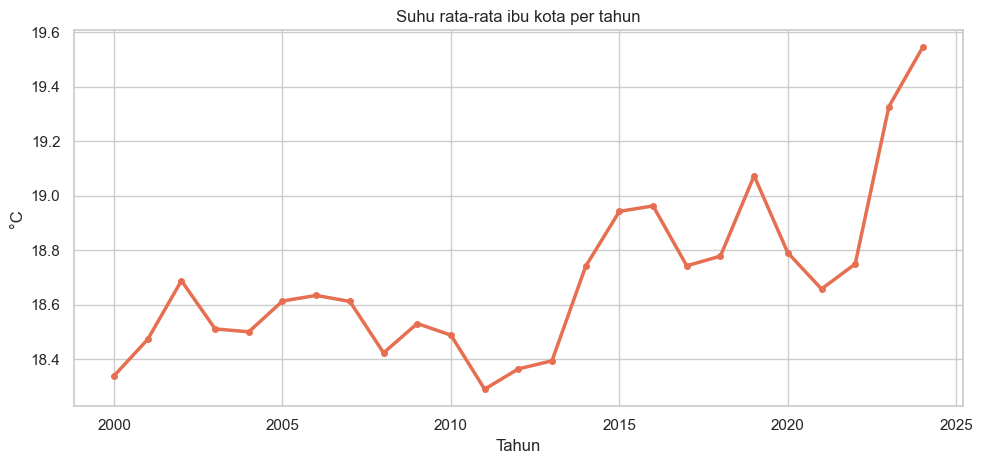

In [96]:
# 📊 EDA TABEL | fact_climate | suhu rata-rata ibu kota per tahun

tm = clim_c.groupby("year")["avg_temp_c"].mean()
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(tm.index, tm.values, color="#e76f51", lw=2.5, marker="o", ms=4)
ax.set(title="Suhu rata-rata ibu kota per tahun", xlabel="Tahun", ylabel="°C")
plt.tight_layout(); plt.show()

In [97]:
# 💡 TEMUAN | fact_climate | kesimpulan EDA tabel

catat(f"**Temuan EDA tabel.** Suhu rata-rata ibu kota {t_.mean():.1f} °C (rentang {t_.min():.1f} sampai {t_.max():.1f}), curah hujan rata-rata {pr_.mean():,.0f} mm per tahun. "
      "Garis suhu adalah rata-rata dari ibu kota negara dalam scope, **bukan** suhu global, sehingga jangan ditafsirkan sebagai bukti pemanasan global.")

**Temuan EDA tabel.** Suhu rata-rata ibu kota 18.7 °C (rentang 3.2 sampai 29.6), curah hujan rata-rata 1,105 mm per tahun. Garis suhu adalah rata-rata dari ibu kota negara dalam scope, **bukan** suhu global, sehingga jangan ditafsirkan sebagai bukti pemanasan global.

## 7. Menggabungkan tabel
Setelah keempat tabel bersih, barulah digabung. Tabel pertanian dipakai sebagai dasar (satu baris = satu negara-tahun yang punya data pertanian), lalu tabel ekonomi dan iklim ditempelkan lewat **`country_id` + `year`**, dan keterangan negara ditempelkan lewat `country_id` (inilah foreign key bekerja).

Dua hal diperiksa: (1) berapa baris pertanian yang punya pasangan di tabel lain, dan (2) jumlah baris **tidak bertambah** setelah digabung (bukti tidak ada baris ganda).

In [98]:
# 🔗 PENGGABUNGAN | periksa pasangan kunci (negara, tahun) sebelum digabung

kunci_agri = set(zip(agri_c["country_id"], agri_c["year"]))
for nama, t in [("fact_economic", econ_c), ("fact_climate", clim_c)]:
    ada = set(zip(t["country_id"], t["year"]))
    print(f"{nama}: {len(kunci_agri & ada):,} dari {len(kunci_agri):,} baris pertanian punya pasangan")

fact_economic: 1,050 dari 1,050 baris pertanian punya pasangan
fact_climate: 1,050 dari 1,050 baris pertanian punya pasangan


In [99]:
# 🔗 PENGGABUNGAN | gabungkan tabel dan buat fitur turunan (log GDP, log populasi)

df = (agri_c
      .merge(econ_c, on=KUNCI, how="left")
      .merge(clim_c, on=KUNCI, how="left")
      .merge(dim_c[["country_id", "country_code", "country_name", "region", "income_level"]], on="country_id", how="left")
      .sort_values(["country_code", "year"]).reset_index(drop=True))
assert len(df) == len(agri_c), "Jumlah baris berubah setelah penggabungan (ada baris ganda)"

# GDP dan populasi sangat miring ke kanan, sehingga dipakai dalam skala log10
df["log_gdp"] = np.log10(df["gdp_per_capita_usd"])
df["log_pop"] = np.log10(df["population"])
print(f"Data gabungan: {df.shape[0]:,} baris x {df.shape[1]} kolom (sama dengan tabel pertanian bersih: {len(agri_c):,} baris)")

Data gabungan: 1,050 baris x 19 kolom (sama dengan tabel pertanian bersih: 1,050 baris)


In [100]:
# 🔗 PENGGABUNGAN | tiga baris pertama data gabungan

display(df.head(3))

,country_id,year,cereal_yield_kg_ha,fertilizer_kg_ha,arable_land_pct,agri_value_added_pct,agri_employment_pct,outlier_yield,gdp_per_capita_usd,population,avg_temp_c,total_precip_mm,months_with_data,country_code,country_name,region,income_level,log_gdp,log_pop
0,1,2000,"3,447.50",31.21,10.10,4.68,11.45,False,"7,637.01","37,213,984.00",17.37,"1,372.50",12.00,ARG,Argentina,Latin America & Caribbean,Upper middle income,3.88,7.57
1,1,2001,"3,210.70",31.06,10.14,4.57,11.41,False,"7,141.48","37,624,825.00",18.09,"1,387.00",12.00,ARG,Argentina,Latin America & Caribbean,Upper middle income,3.85,7.58
2,1,2002,"3,237.00",30.23,10.18,10.21,11.61,False,"2,569.70","38,029,349.00",17.74,"1,408.90",12.00,ARG,Argentina,Latin America & Caribbean,Upper middle income,3.41,7.58


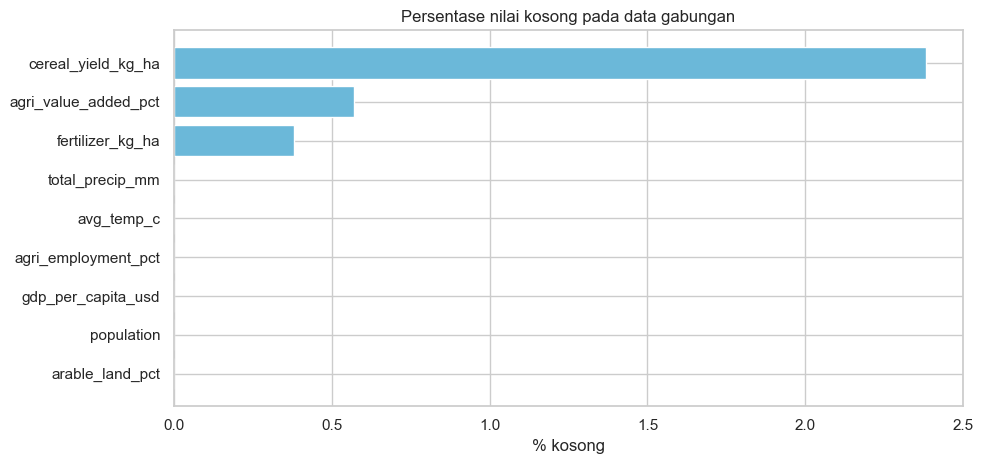

In [101]:
# 🔗 PENGGABUNGAN | persentase nilai kosong pada data gabungan

kosong_gab = (df[["cereal_yield_kg_ha", "fertilizer_kg_ha", "arable_land_pct", "agri_value_added_pct", "agri_employment_pct",
                  "gdp_per_capita_usd", "population", "avg_temp_c", "total_precip_mm"]].isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(kosong_gab.index, kosong_gab.values, color="#6bb8d9")
ax.set(title="Persentase nilai kosong pada data gabungan", xlabel="% kosong")
plt.tight_layout(); plt.show()

In [102]:
# 💡 TEMUAN | kesimpulan penggabungan

catat(f"**Temuan penggabungan.** Data gabungan berisi {len(df):,} baris. Kolom dengan kosong terbanyak: `{kosong_gab.index[-1]}` ({kosong_gab.iloc[-1]:.1f}%). "
      "Kekosongan ini diperlakukan per analisis: dibuang pada pasangan variabel yang dipakai, atau diimputasi di dalam pipeline model supaya tidak bocor.")

**Temuan penggabungan.** Data gabungan berisi 1,050 baris. Kolom dengan kosong terbanyak: `cereal_yield_kg_ha` (2.4%). Kekosongan ini diperlakukan per analisis: dibuang pada pasangan variabel yang dipakai, atau diimputasi di dalam pipeline model supaya tidak bocor.

In [103]:
# 🔗 PENGGABUNGAN | ringkasan assessing semua tabel: sebelum vs sesudah cleaning

ringkasan_sebelum = pd.DataFrame(sebelum).set_index("tabel")
ringkasan_sesudah = pd.DataFrame(sesudah).set_index("tabel")
banding_semua = ringkasan_sebelum.join(ringkasan_sesudah, lsuffix="_sebelum", rsuffix="_sesudah")
display(banding_semua[[c for k in ringkasan_sebelum.columns for c in (f"{k}_sebelum", f"{k}_sesudah")]])

,baris_sebelum,baris_sesudah,total_null_sebelum,total_null_sesudah,duplikat_baris_sebelum,duplikat_baris_sesudah,duplikat_kunci_sebelum,duplikat_kunci_sesudah,nilai_tidak_valid_sebelum,nilai_tidak_valid_sesudah
tabel,,,,,,,,,,
dim_country,42,42,0,0,0,0,0,0,0,0
fact_agriculture,1050,1050,35,35,0,0,0,0,0,0
fact_economic,1050,1050,0,0,0,0,0,0,0,0
fact_climate,1050,1050,0,0,0,0,0,0,0,0


## 8. EDA data gabungan (menjawab Q1–Q3)
Setelah tabel digabung, barulah ketiga pertanyaan analisis dijawab.

### Q1. Negara dan kawasan mana yang punya hasil serealia tertinggi?
**Visual:** bar chart horizontal, karena tujuannya membandingkan peringkat antar kategori. Dipakai rata-rata periode terbaru agar tidak bergantung pada satu tahun yang mungkin kosong.

In [104]:
# 📈 EDA GABUNGAN | Q1 | hitung rata-rata hasil serealia per negara (periode terbaru)

PERIODE = (2018, 2024)
p = df[df["year"].between(*PERIODE)]
q1_tab = (p.groupby(["country_code", "country_name", "region"], as_index=False)["cereal_yield_kg_ha"].mean()
            .dropna().sort_values("cereal_yield_kg_ha", ascending=False).reset_index(drop=True))
q1_tab["peringkat"] = q1_tab.index + 1
display(q1_tab.head(10))

,country_code,country_name,region,cereal_yield_kg_ha,peringkat
0,NZL,New Zealand,East Asia & Pacific,"8,582.51",1
1,USA,United States,North America,"8,200.30",2
2,NLD,Netherlands,Europe & Central Asia,"8,020.59",3
3,GBR,United Kingdom,Europe & Central Asia,"7,051.24",4
4,EGY,"Egypt, Arab Rep.","Middle East, North Africa, Afghanistan & Pakistan","7,016.29",5
5,DEU,Germany,Europe & Central Asia,"6,883.74",6
6,FRA,France,Europe & Central Asia,"6,870.99",7
7,KOR,"Korea, Rep.",East Asia & Pacific,"6,564.40",8
8,CHN,China,East Asia & Pacific,"6,333.17",9
9,JPN,Japan,East Asia & Pacific,"6,269.47",10


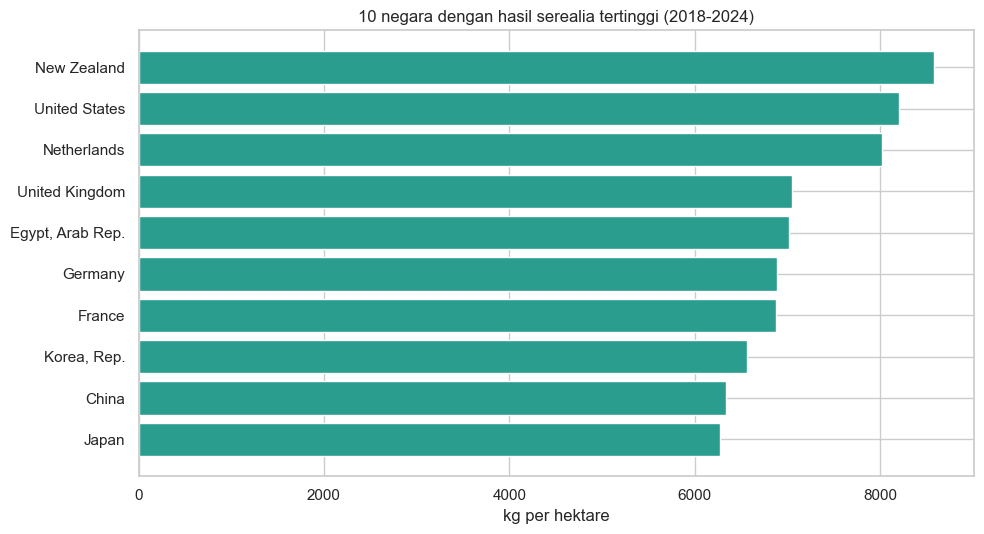

In [105]:
# 📈 EDA GABUNGAN | Q1 | grafik 10 negara tertinggi

top = q1_tab.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top["country_name"], top["cereal_yield_kg_ha"], color="#2a9d8f")
ax.set(title=f"10 negara dengan hasil serealia tertinggi ({PERIODE[0]}-{PERIODE[1]})", xlabel="kg per hektare")
plt.tight_layout(); plt.show()

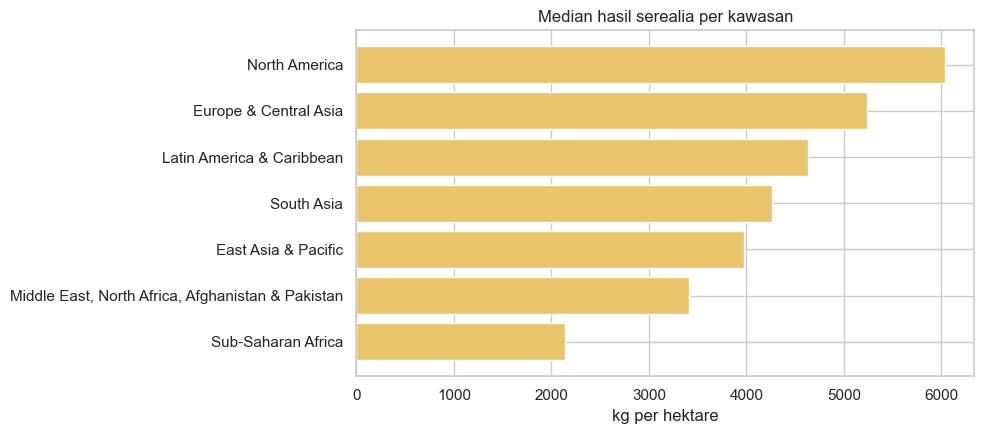

In [106]:
# 📈 EDA GABUNGAN | Q1 | grafik median per kawasan

reg = q1_tab.groupby("region")["cereal_yield_kg_ha"].median().sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(reg.index, reg.values, color="#e9c46a")
ax.set(title="Median hasil serealia per kawasan", xlabel="kg per hektare")
plt.tight_layout(); plt.show()

In [107]:
# 💡 TEMUAN | Q1 | jawaban Q1

t, r = q1_tab.iloc[0], reg.index[-1]
teks = (f"**Temuan Q1.** Hasil serealia tertinggi pada periode ini dicapai **{t['country_name']}** "
        f"(rata-rata {t['cereal_yield_kg_ha']:,.0f} kg/ha), dan kawasan dengan median tertinggi adalah **{r}**. ")
idn = q1_tab[q1_tab["country_code"] == "IDN"]
if not idn.empty:
    i = idn.iloc[0]
    teks += (f"Indonesia berada di peringkat **{int(i['peringkat'])} dari {len(q1_tab)}** negara "
             f"dengan rata-rata {i['cereal_yield_kg_ha']:,.0f} kg/ha.")
catat(teks)

**Temuan Q1.** Hasil serealia tertinggi pada periode ini dicapai **New Zealand** (rata-rata 8,583 kg/ha), dan kawasan dengan median tertinggi adalah **North America**. Indonesia berada di peringkat **12 dari 41** negara dengan rata-rata 5,334 kg/ha.

### Q2. Apakah pemakaian pupuk berkaitan dengan hasil serealia?
**Visual:** scatter plot, karena yang ditanyakan adalah hubungan dua variabel numerik. Sumbu pupuk memakai skala log karena sebarannya sangat miring. Kekuatan hubungan diukur dengan korelasi **Spearman** (berbasis peringkat, tahan outlier) dan **Pearson** pada pupuk skala log.

In [108]:
# 📈 EDA GABUNGAN | Q2 | hitung korelasi pupuk vs hasil serealia

def kekuatan(r):
    a = abs(r)
    k = "sangat lemah" if a < .2 else "lemah" if a < .4 else "sedang" if a < .6 else "kuat" if a < .8 else "sangat kuat"
    return f"{k}, {'positif' if r > 0 else 'negatif'}"

d2 = df[["country_code", "income_level", "fertilizer_kg_ha", "cereal_yield_kg_ha"]].dropna()
d2 = d2[d2["fertilizer_kg_ha"] > 0].copy()
d2["log_fert"] = np.log10(d2["fertilizer_kg_ha"])

rho, p_rho = stats.spearmanr(d2["fertilizer_kg_ha"], d2["cereal_yield_kg_ha"])
r_p, p_p = stats.pearsonr(d2["log_fert"], d2["cereal_yield_kg_ha"])
d2_neg = d2.groupby("country_code")[["fertilizer_kg_ha", "cereal_yield_kg_ha"]].mean()
rho_neg, p_neg = stats.spearmanr(d2_neg["fertilizer_kg_ha"], d2_neg["cereal_yield_kg_ha"])

print(f"Pasangan negara-tahun         : {len(d2):,}")
print(f"Spearman (negara-tahun)       : {rho:.3f}  ({kekuatan(rho)})")
print(f"Pearson (pupuk skala log)     : {r_p:.3f}")
print(f"Spearman (rata-rata per negara): {rho_neg:.3f}  dari {len(d2_neg)} negara")

Pasangan negara-tahun         : 1,021
Spearman (negara-tahun)       : 0.670  (kuat, positif)
Pearson (pupuk skala log)     : 0.611
Spearman (rata-rata per negara): 0.676  dari 41 negara


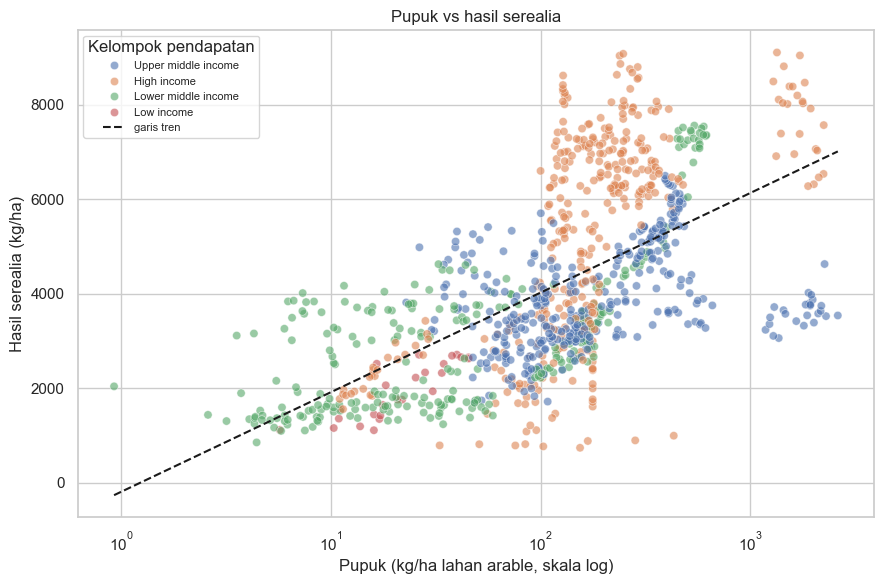

In [109]:
# 📈 EDA GABUNGAN | Q2 | scatter pupuk vs hasil serealia

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=d2, x="fertilizer_kg_ha", y="cereal_yield_kg_ha", hue="income_level", alpha=.6, ax=ax)
ax.set_xscale("log")
b, a = np.polyfit(d2["log_fert"], d2["cereal_yield_kg_ha"], 1)
xs = np.linspace(d2["log_fert"].min(), d2["log_fert"].max(), 100)
ax.plot(10 ** xs, a + b * xs, "k--", lw=1.5, label="garis tren")
ax.set(title="Pupuk vs hasil serealia", xlabel="Pupuk (kg/ha lahan arable, skala log)", ylabel="Hasil serealia (kg/ha)")
ax.legend(title="Kelompok pendapatan", fontsize=8)
plt.tight_layout(); plt.show()

In [110]:
# 💡 TEMUAN | Q2 | jawaban Q2

catat(f"**Temuan Q2.** Pada {len(d2):,} pasangan negara-tahun, korelasi Spearman = **{rho:.2f}** ({kekuatan(rho)}); "
      f"Pearson pada pupuk skala log = {r_p:.2f}. Bila dirata-ratakan per negara ({len(d2_neg)} negara), Spearman = {rho_neg:.2f}, "
      "sehingga kesimpulan tidak hanya bergantung pada banyaknya tahun per negara. "
      "**Penafsiran hati-hati:** ini keterkaitan, bukan sebab-akibat. Negara yang memakai banyak pupuk umumnya juga lebih kaya, "
      "punya irigasi, dan benih unggul, sehingga pupuk bisa ikut mewakili faktor-faktor lain itu. "
      "Nilai p tidak ditonjolkan karena pengamatan negara-tahun tidak independen (satu negara muncul berkali-kali).")

**Temuan Q2.** Pada 1,021 pasangan negara-tahun, korelasi Spearman = **0.67** (kuat, positif); Pearson pada pupuk skala log = 0.61. Bila dirata-ratakan per negara (41 negara), Spearman = 0.68, sehingga kesimpulan tidak hanya bergantung pada banyaknya tahun per negara. **Penafsiran hati-hati:** ini keterkaitan, bukan sebab-akibat. Negara yang memakai banyak pupuk umumnya juga lebih kaya, punya irigasi, dan benih unggul, sehingga pupuk bisa ikut mewakili faktor-faktor lain itu. Nilai p tidak ditonjolkan karena pengamatan negara-tahun tidak independen (satu negara muncul berkali-kali).

### Q3. Apakah ekonomi dan iklim berkaitan dengan hasil serealia, dan bagaimana posisi Indonesia?
Empat alat dengan tujuan berbeda: **heatmap korelasi** (seluruh hubungan sekaligus), **boxplot** (perbandingan antar kelompok pendapatan), **scatter GDP** (bentuk hubungan), dan **garis tren** (Indonesia vs ASEAN). Perbedaan antar kelompok diuji dengan **Kruskal-Wallis**.

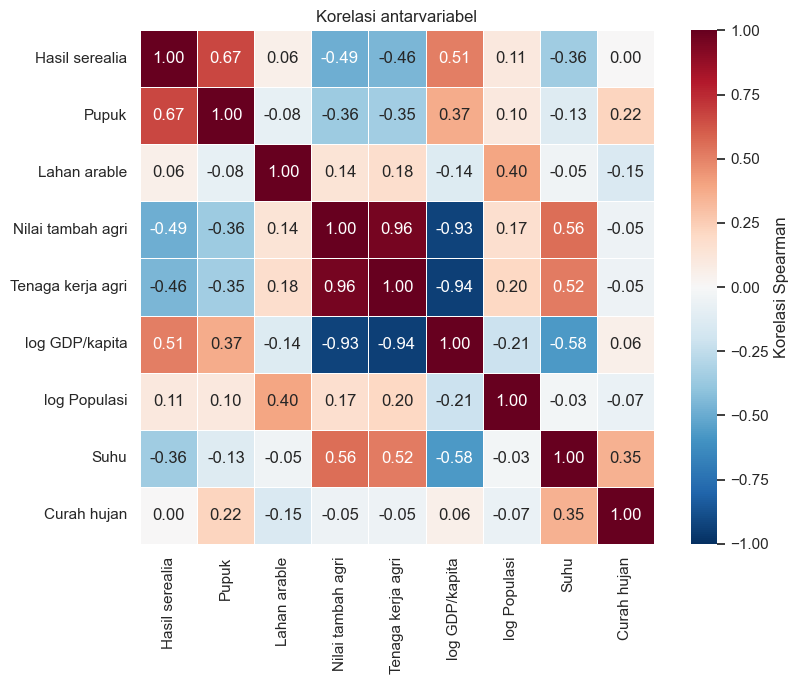

In [111]:
# 📈 EDA GABUNGAN | Q3 | heatmap korelasi antarvariabel

KOL = {"cereal_yield_kg_ha": "Hasil serealia", "fertilizer_kg_ha": "Pupuk", "arable_land_pct": "Lahan arable",
       "agri_value_added_pct": "Nilai tambah agri", "agri_employment_pct": "Tenaga kerja agri",
       "log_gdp": "log GDP/kapita", "log_pop": "log Populasi", "avg_temp_c": "Suhu", "total_precip_mm": "Curah hujan"}
corr = df[list(KOL)].rename(columns=KOL).corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax, cbar_kws={"label": "Korelasi Spearman"})
ax.set_title("Korelasi antarvariabel")
plt.tight_layout(); plt.show()

In [112]:
# 💡 TEMUAN | Q3 | pembacaan heatmap

kor_y = corr["Hasil serealia"].drop("Hasil serealia")
top3 = kor_y.reindex(kor_y.abs().sort_values(ascending=False).index).head(3)
catat("**Temuan heatmap.** Variabel yang paling berkaitan dengan hasil serealia: " +
      "; ".join(f"**{k}** ({v:.2f}, {kekuatan(v)})" for k, v in top3.items()) +
      ". Tanda negatif pada *nilai tambah agri* kemungkinan mencerminkan tingkat pembangunan (negara miskin porsi pertaniannya besar), "
      "bukan dampak buruk pertanian terhadap hasil. Hubungan antar-variabel penjelas (misalnya GDP dan pupuk) juga saling tumpang tindih.")

**Temuan heatmap.** Variabel yang paling berkaitan dengan hasil serealia: **Pupuk** (0.67, kuat, positif); **log GDP/kapita** (0.51, sedang, positif); **Nilai tambah agri** (-0.49, sedang, negatif). Tanda negatif pada *nilai tambah agri* kemungkinan mencerminkan tingkat pembangunan (negara miskin porsi pertaniannya besar), bukan dampak buruk pertanian terhadap hasil. Hubungan antar-variabel penjelas (misalnya GDP dan pupuk) juga saling tumpang tindih.

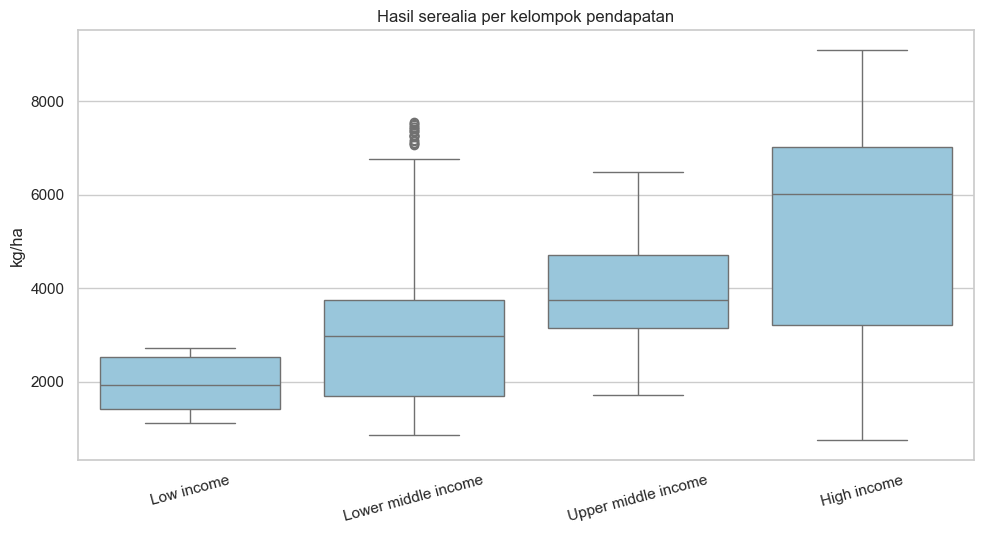

In [113]:
# 📈 EDA GABUNGAN | Q3 | boxplot hasil serealia per kelompok pendapatan

URUT = ["Low income", "Lower middle income", "Upper middle income", "High income"]
urut = [u for u in URUT if u in df["income_level"].unique()] or sorted(df["income_level"].dropna().unique())

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df, x="income_level", y="cereal_yield_kg_ha", order=urut, ax=ax, color="#8ecae6")
ax.set(title="Hasil serealia per kelompok pendapatan", xlabel="", ylabel="kg/ha")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

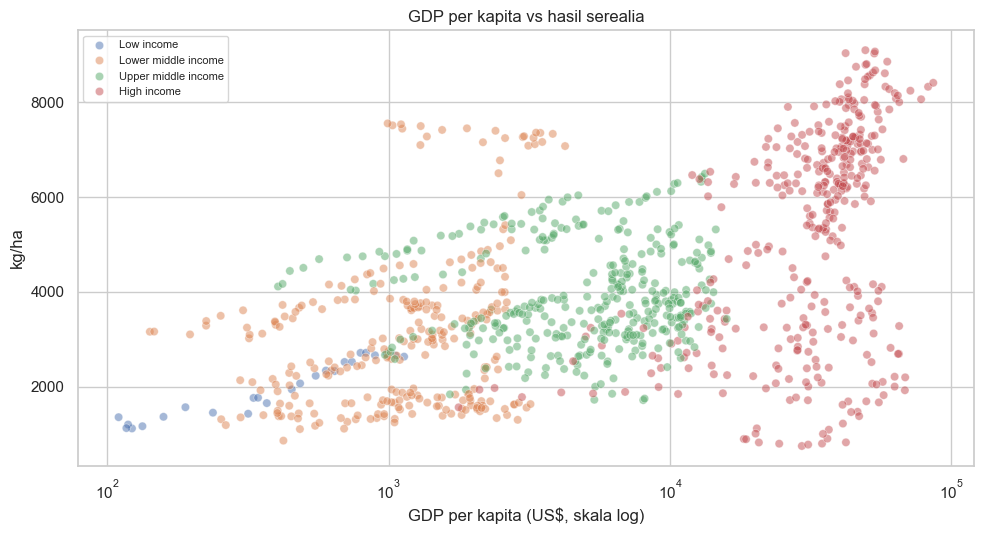

In [114]:
# 📈 EDA GABUNGAN | Q3 | scatter GDP per kapita vs hasil serealia

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=df, x="gdp_per_capita_usd", y="cereal_yield_kg_ha", hue="income_level", hue_order=urut, alpha=.5, ax=ax)
ax.set_xscale("log")
ax.set(title="GDP per kapita vs hasil serealia", xlabel="GDP per kapita (US$, skala log)", ylabel="kg/ha")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [115]:
# 📈 EDA GABUNGAN | Q3 | uji Kruskal-Wallis dan korelasi GDP

grup = [g["cereal_yield_kg_ha"].dropna() for _, g in df.groupby("income_level")]
grup = [g for g in grup if len(g) > 2]
h, p_kw = stats.kruskal(*grup)
d3 = df[["log_gdp", "cereal_yield_kg_ha"]].dropna()
rho_g, p_g = stats.spearmanr(d3["log_gdp"], d3["cereal_yield_kg_ha"])
med = df.groupby("income_level")["cereal_yield_kg_ha"].median().reindex(urut)

print(f"Spearman GDP vs hasil serealia: {rho_g:.3f}  ({kekuatan(rho_g)})")
print(f"Kruskal-Wallis antar kelompok pendapatan: H = {h:.1f}, p = {p_kw:.3g}")
print("\nMedian hasil serealia per kelompok:"); print(med.round(0).to_string())

Spearman GDP vs hasil serealia: 0.509  (sedang, positif)
Kruskal-Wallis antar kelompok pendapatan: H = 207.5, p = 1.01e-44

Median hasil serealia per kelompok:
income_level
Low income            1,940.00
Lower middle income   2,970.00
Upper middle income   3,748.00
High income           6,011.00


In [116]:
# 💡 TEMUAN | Q3 | pembacaan GDP dan kelompok pendapatan

catat(f"**Temuan.** Korelasi Spearman antara GDP per kapita dan hasil serealia = **{rho_g:.2f}** ({kekuatan(rho_g)}). "
      f"Median hasil serealia per kelompok: " + "; ".join(f"{k} = {v:,.0f}" for k, v in med.items() if pd.notna(v)) + ". "
      f"Uji Kruskal-Wallis: H = {h:.1f}, p = {p_kw:.3g} → perbedaan antar kelompok pendapatan "
      f"{'**signifikan**' if p_kw < .05 else '**tidak signifikan**'} pada α = 0,05. "
      "Kelompok pendapatan memakai klasifikasi World Bank terkini untuk seluruh tahun. "
      "Ingat: GDP tidak 'menyebabkan' hasil panen naik; keduanya sama-sama berkaitan dengan teknologi, infrastruktur, dan investasi.")

**Temuan.** Korelasi Spearman antara GDP per kapita dan hasil serealia = **0.51** (sedang, positif). Median hasil serealia per kelompok: Low income = 1,940; Lower middle income = 2,970; Upper middle income = 3,748; High income = 6,011. Uji Kruskal-Wallis: H = 207.5, p = 1.01e-44 → perbedaan antar kelompok pendapatan **signifikan** pada α = 0,05. Kelompok pendapatan memakai klasifikasi World Bank terkini untuk seluruh tahun. Ingat: GDP tidak 'menyebabkan' hasil panen naik; keduanya sama-sama berkaitan dengan teknologi, infrastruktur, dan investasi.

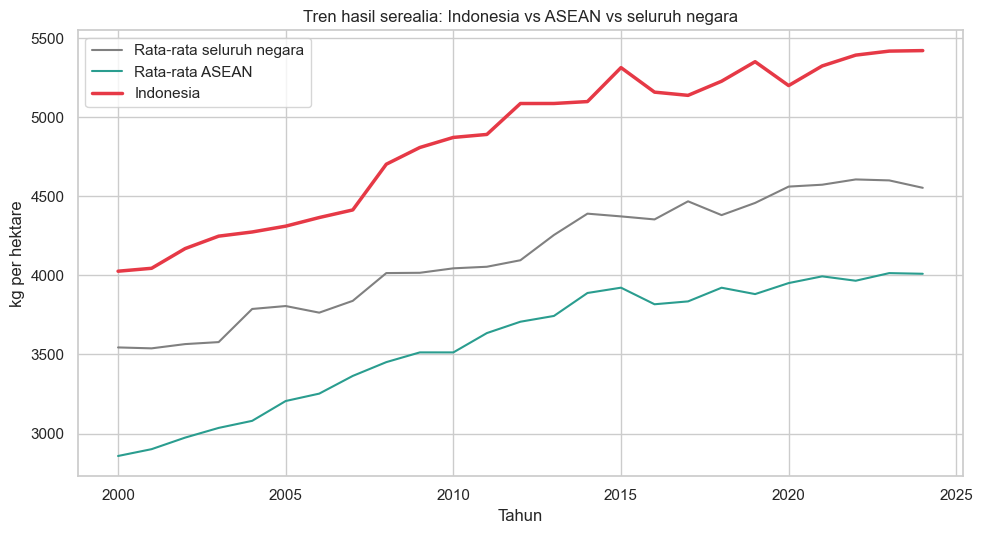

In [117]:
# 📈 EDA GABUNGAN | Q3 | tren hasil serealia: Indonesia vs ASEAN vs seluruh negara

ASEAN = ["IDN", "MYS", "THA", "VNM", "PHL", "SGP", "KHM", "LAO", "MMR", "BRN"]
semua = df.groupby("year")["cereal_yield_kg_ha"].mean()
asean = df[df["country_code"].isin(ASEAN)].groupby("year")["cereal_yield_kg_ha"].mean()
indo = df[df["country_code"] == "IDN"].set_index("year")["cereal_yield_kg_ha"]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(semua.index, semua.values, label="Rata-rata seluruh negara", color="gray")
ax.plot(asean.index, asean.values, label="Rata-rata ASEAN", color="#2a9d8f")
if not indo.dropna().empty:
    ax.plot(indo.index, indo.values, label="Indonesia", color="#e63946", lw=2.5)
ax.set(title="Tren hasil serealia: Indonesia vs ASEAN vs seluruh negara", xlabel="Tahun", ylabel="kg per hektare")
ax.legend(); plt.tight_layout(); plt.show()

In [118]:
# 💡 TEMUAN | Q3 | pembacaan tren Indonesia

teks = "**Temuan tren.** "
if not indo.dropna().empty:
    a, b = indo.dropna().index.min(), indo.dropna().index.max()
    v0, v1 = indo[a], indo[b]
    teks += (f"Hasil serealia Indonesia berubah dari {v0:,.0f} kg/ha ({a}) menjadi {v1:,.0f} kg/ha ({b}), "
             f"yaitu {((v1 / v0) - 1) * 100:+.0f}%. ")
    if b in asean.index:
        teks += f"Pada {b}, rata-rata ASEAN = {asean[b]:,.0f} kg/ha dan rata-rata seluruh negara dalam scope = {semua[b]:,.0f} kg/ha."
else:
    teks += "Data Indonesia tidak tersedia pada scope ini."
catat(teks)

**Temuan tren.** Hasil serealia Indonesia berubah dari 4,026 kg/ha (2000) menjadi 5,421 kg/ha (2024), yaitu +35%. Pada 2024, rata-rata ASEAN = 4,010 kg/ha dan rata-rata seluruh negara dalam scope = 4,554 kg/ha.

## 9. Q4: model klasifikasi tingkat hasil serealia
**Pertanyaan:** dapatkah karakteristik pertanian, ekonomi, dan iklim mengklasifikasikan hasil serealia menjadi **Rendah / Sedang / Tinggi**?

**Rancangan yang menjaga kualitas analisis:**
- **Target** dibuat dari tertil (sepertiga) hasil serealia. Ambang tertil dihitung **hanya dari data latih**, supaya data uji tidak ikut menentukan label.
- **Hasil serealia tidak dipakai sebagai fitur** (itu target itu sendiri).
- **Pemisahan latih/uji per negara** (*group split*): satu negara tidak muncul di kedua sisi. Kalau diacak per baris, tahun-tahun berbeda dari negara yang sama bocor ke data uji dan skornya terlalu optimistis.
- **Imputasi nilai kosong dilakukan di dalam pipeline** (hanya belajar dari data latih), bukan sebelum pemisahan data.
- Ada **baseline** sebagai pembanding, supaya jelas apakah model benar-benar belajar.
- Fokusnya pada proses dan interpretasi, bukan mengejar akurasi.

### 9.1 Menyiapkan data

In [119]:
# 🤖 MODEL | persiapan | impor library model

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.base import clone

In [120]:
# 🤖 MODEL | persiapan | tentukan fitur (X) dan kelas target (y)

NUM = ["fertilizer_kg_ha", "arable_land_pct", "agri_value_added_pct", "agri_employment_pct",
       "log_gdp", "log_pop", "avg_temp_c", "total_precip_mm", "year"]
CAT = ["region", "income_level"]
FITUR = NUM + CAT
LABEL = ["Rendah", "Sedang", "Tinggi"]
print("Fitur numerik  :", NUM)
print("Fitur kategori :", CAT)
print("Kelas target   :", LABEL)

Fitur numerik  : ['fertilizer_kg_ha', 'arable_land_pct', 'agri_value_added_pct', 'agri_employment_pct', 'log_gdp', 'log_pop', 'avg_temp_c', 'total_precip_mm', 'year']
Fitur kategori : ['region', 'income_level']
Kelas target   : ['Rendah', 'Sedang', 'Tinggi']


In [121]:
# 🤖 MODEL | persiapan | buang baris yang hasil serealianya kosong

dm = df.dropna(subset=["cereal_yield_kg_ha"]).reset_index(drop=True)
for c in CAT:
    dm[c] = dm[c].astype(object).where(dm[c].notna(), np.nan)
print(f"{len(df):,} baris data bersih -> {len(df) - len(dm)} baris dibuang (hasil serealia kosong) -> {len(dm):,} baris dipakai")

1,050 baris data bersih -> 25 baris dibuang (hasil serealia kosong) -> 1,025 baris dipakai


In [122]:
# 🤖 MODEL | persiapan | bagi data latih dan uji PER NEGARA

idx_tr, idx_te = next(GroupShuffleSplit(n_splits=1, test_size=.25, random_state=42).split(dm, groups=dm["country_code"]))
tr, te = dm.iloc[idx_tr], dm.iloc[idx_te]
print(f"Data latih: {len(tr):,} baris / {tr['country_code'].nunique()} negara")
print(f"Data uji  : {len(te):,} baris / {te['country_code'].nunique()} negara")
print("Negara yang ada di kedua sisi:", len(set(tr['country_code']) & set(te['country_code'])), "(harus 0)")

Data latih: 750 baris / 30 negara
Data uji  : 275 baris / 11 negara
Negara yang ada di kedua sisi: 0 (harus 0)


In [123]:
# 🤖 MODEL | persiapan | buat label Rendah/Sedang/Tinggi dari tertil DATA LATIH

b1, b2 = tr["cereal_yield_kg_ha"].quantile([1 / 3, 2 / 3])
def kategori(v):
    return np.where(v <= b1, "Rendah", np.where(v <= b2, "Sedang", "Tinggi"))
y_tr, y_te = kategori(tr["cereal_yield_kg_ha"]), kategori(te["cereal_yield_kg_ha"])

print(f"Ambang dari data latih: Rendah <= {b1:,.0f} < Sedang <= {b2:,.0f} < Tinggi (kg/ha)")
print("Sebaran kelas latih:", pd.Series(y_tr).value_counts().reindex(LABEL).to_dict())
print("Sebaran kelas uji  :", pd.Series(y_te).value_counts().reindex(LABEL).to_dict())

Ambang dari data latih: Rendah <= 2,814 < Sedang <= 4,170 < Tinggi (kg/ha)
Sebaran kelas latih: {'Rendah': 250, 'Sedang': 250, 'Tinggi': 250}
Sebaran kelas uji  : {'Rendah': 31, 'Sedang': 84, 'Tinggi': 160}


### 9.2 Memahami target dan fitur
Model belajar dari pasangan **input → jawaban**:

- **Target (y), yaitu jawaban yang ingin ditebak:** tingkat hasil serealia suatu negara pada suatu tahun: **Rendah, Sedang, atau Tinggi**. Label ini dibuat dari angka hasil serealia (kg/ha) dengan memotongnya menjadi tiga kelompok sama besar (*tertil*).
- **Fitur (X), yaitu keterangan yang diberikan ke model untuk menebak:** pupuk, lahan arable, nilai tambah dan tenaga kerja pertanian, GDP, populasi, suhu, curah hujan, tahun, kawasan, dan kelompok pendapatan.
- **Hasil serealia itu sendiri tidak boleh menjadi fitur**, karena itu adalah jawabannya. Memasukkannya sama dengan memberi contekan.
- Satu **baris data** = satu negara pada satu tahun. Model melihat fitur baris itu, lalu menebak labelnya.

In [124]:
# 🤖 MODEL | penjelasan | daftar fitur dan artinya

FITUR_ARTI = pd.DataFrame([
    ("fertilizer_kg_ha", "Pemakaian pupuk (kg per hektare lahan arable)", "numerik", "fact_agriculture"),
    ("arable_land_pct", "Lahan arable (% dari luas lahan)", "numerik", "fact_agriculture"),
    ("agri_value_added_pct", "Nilai tambah pertanian (% dari PDB)", "numerik", "fact_agriculture"),
    ("agri_employment_pct", "Tenaga kerja di pertanian (% dari total)", "numerik", "fact_agriculture"),
    ("log_gdp", "GDP per kapita (skala log10)", "numerik", "fact_economic"),
    ("log_pop", "Populasi (skala log10)", "numerik", "fact_economic"),
    ("avg_temp_c", "Suhu rata-rata tahunan (°C)", "numerik", "fact_climate"),
    ("total_precip_mm", "Curah hujan tahunan (mm)", "numerik", "fact_climate"),
    ("year", "Tahun pengamatan", "numerik", "-"),
    ("region", "Kawasan negara", "kategori", "dim_country"),
    ("income_level", "Kelompok pendapatan World Bank", "kategori", "dim_country"),
], columns=["fitur (X)", "arti", "jenis", "asal tabel"])
display(FITUR_ARTI)

,fitur (X),arti,jenis,asal tabel
0,fertilizer_kg_ha,Pemakaian pupuk (kg per hektare lahan arable),numerik,fact_agriculture
1,arable_land_pct,Lahan arable (% dari luas lahan),numerik,fact_agriculture
2,agri_value_added_pct,Nilai tambah pertanian (% dari PDB),numerik,fact_agriculture
3,agri_employment_pct,Tenaga kerja di pertanian (% dari total),numerik,fact_agriculture
4,log_gdp,GDP per kapita (skala log10),numerik,fact_economic
5,log_pop,Populasi (skala log10),numerik,fact_economic
6,avg_temp_c,Suhu rata-rata tahunan (°C),numerik,fact_climate
7,total_precip_mm,Curah hujan tahunan (mm),numerik,fact_climate
8,year,Tahun pengamatan,numerik,-
9,region,Kawasan negara,kategori,dim_country


In [125]:
# 🤖 MODEL | penjelasan | contoh satu baris: fitur (X) menjadi target (y)

contoh = dm[dm["country_code"] == "IDN"].sort_values("year").tail(1)
if not contoh.empty:
    r = contoh.iloc[0]
    print(f"Contoh satu baris data: {r['country_name']}, tahun {int(r['year'])}")
    print("Fitur (X) yang diberikan ke model:")
    display(r[FITUR].to_frame("nilai"))
    y_contoh = kategori(np.array([r["cereal_yield_kg_ha"]]))[0]
    print(f"Hasil serealia sebenarnya = {r['cereal_yield_kg_ha']:,.0f} kg/ha  ->  target (y) = {y_contoh}")
    print(f"(Rendah bila <= {b1:,.0f}; Sedang bila <= {b2:,.0f}; selebihnya Tinggi)")
else:
    print("Indonesia tidak ada pada data model.")

Contoh satu baris data: Indonesia, tahun 2024
Fitur (X) yang diberikan ke model:


,nilai
fertilizer_kg_ha,312.64
arable_land_pct,9.35
agri_value_added_pct,12.61
agri_employment_pct,27.96
log_gdp,3.69
log_pop,8.45
avg_temp_c,28.13
total_precip_mm,"2,397.30"
year,2024
region,East Asia & Pacific


Hasil serealia sebenarnya = 5,421 kg/ha  ->  target (y) = Tinggi
(Rendah bila <= 2,814; Sedang bila <= 4,170; selebihnya Tinggi)


### 9.3 Melatih dan membandingkan model

In [126]:
# 🤖 MODEL | pipeline | siapkan pra-pemrosesan fitur dan daftar model

pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
])
MODEL = {
    "Baseline (kelas terbanyak)": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}
print("Pra-pemrosesan: fitur numerik diisi median; fitur kategori diisi nilai terbanyak lalu diubah menjadi kolom 0/1 (one-hot).")
print("Model:", list(MODEL))

Pra-pemrosesan: fitur numerik diisi median; fitur kategori diisi nilai terbanyak lalu diubah menjadi kolom 0/1 (one-hot).
Model: ['Baseline (kelas terbanyak)', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


In [127]:
# 🤖 MODEL | pipeline | latih keempat model pada data latih

hasil, terlatih, prediksi = [], {}, {}
for nama, clf in MODEL.items():
    pipa = Pipeline([("pre", pre), ("clf", clf)]).fit(tr[FITUR], y_tr)
    pred = pipa.predict(te[FITUR])
    pr, rc, f1, _ = precision_recall_fscore_support(y_te, pred, average="macro", zero_division=0)
    hasil.append({"model": nama, "accuracy": accuracy_score(y_te, pred), "precision_macro": pr, "recall_macro": rc, "f1_macro": f1})
    terlatih[nama], prediksi[nama] = pipa, pred
    print(f"selesai: {nama}")

selesai: Baseline (kelas terbanyak)
selesai: Decision Tree
selesai: Random Forest
selesai: Gradient Boosting


In [128]:
# 🤖 MODEL | evaluasi | tabel perbandingan model (data uji)

tabel_model = pd.DataFrame(hasil).set_index("model")
display(tabel_model.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0))

,accuracy,precision_macro,recall_macro,f1_macro
model,,,,
Baseline (kelas terbanyak),0.113,0.038,0.333,0.068
Decision Tree,0.593,0.460,0.464,0.458
Random Forest,0.691,0.580,0.596,0.585
Gradient Boosting,0.651,0.515,0.515,0.514


In [129]:
# 💡 TEMUAN | evaluasi | model terbaik

kandidat = tabel_model.drop(index="Baseline (kelas terbanyak)")
terbaik = kandidat["f1_macro"].idxmax()
catat(f"**Temuan perbandingan model.** Model terbaik berdasarkan F1-macro adalah **{terbaik}** "
      f"(F1 = {kandidat.loc[terbaik, 'f1_macro']:.3f}, akurasi = {kandidat.loc[terbaik, 'accuracy']:.3f}), dibanding baseline "
      f"F1 = {tabel_model.loc['Baseline (kelas terbanyak)', 'f1_macro']:.3f}. "
      "F1-macro dipakai karena memperlakukan ketiga kelas setara. **Catatan baca baseline:** karena tiga kelas latih sama besar (tertil), baseline "
      "'kelas terbanyak' memilih satu kelas secara arbitrer sehingga skornya bisa sangat rendah; pembanding yang lebih adil untuk tiga kelas seimbang "
      "adalah tebakan acak (F1 ≈ 0.33). Lihat juga sebaran kelas data uji: bila satu kelas mendominasi, akurasi saja dapat menyesatkan.")

**Temuan perbandingan model.** Model terbaik berdasarkan F1-macro adalah **Random Forest** (F1 = 0.585, akurasi = 0.691), dibanding baseline F1 = 0.068. F1-macro dipakai karena memperlakukan ketiga kelas setara. **Catatan baca baseline:** karena tiga kelas latih sama besar (tertil), baseline 'kelas terbanyak' memilih satu kelas secara arbitrer sehingga skornya bisa sangat rendah; pembanding yang lebih adil untuk tiga kelas seimbang adalah tebakan acak (F1 ≈ 0.33). Lihat juga sebaran kelas data uji: bila satu kelas mendominasi, akurasi saja dapat menyesatkan.

### 9.4 Mengevaluasi model terbaik

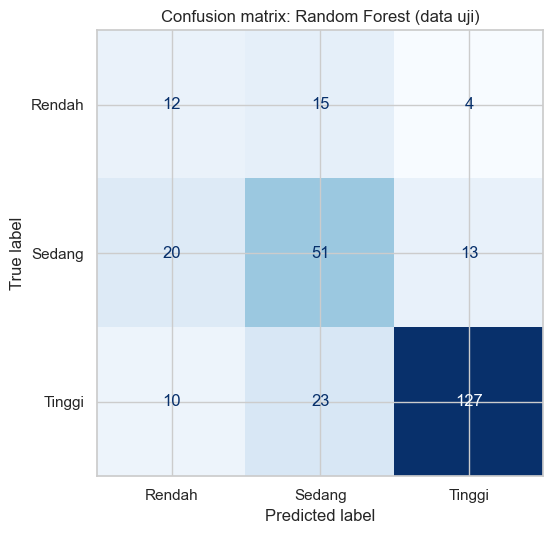

In [130]:
# 🤖 MODEL | evaluasi | confusion matrix model terbaik

best = terlatih[terbaik]
pred_best = prediksi[terbaik]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_te, pred_best, labels=LABEL, ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix: {terbaik} (data uji)")
plt.tight_layout(); plt.show()

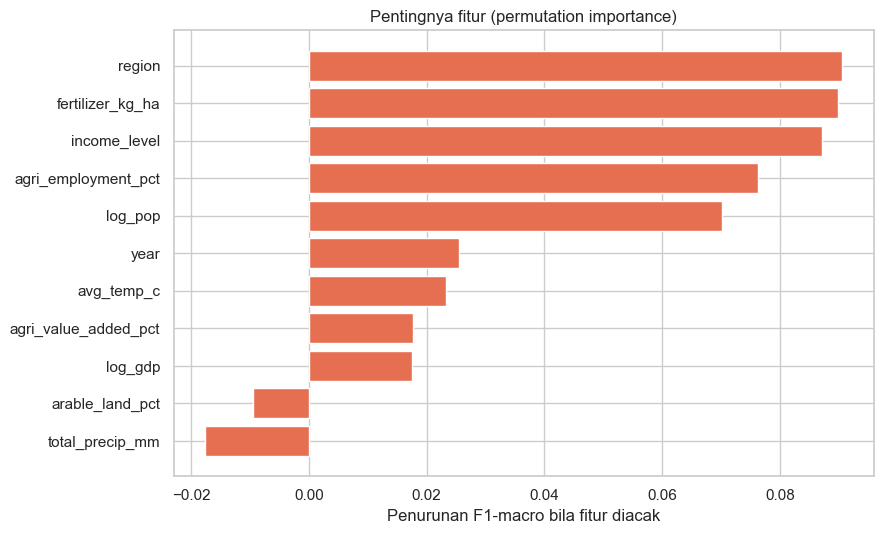

In [131]:
# 🤖 MODEL | evaluasi | pentingnya fitur (permutation importance)

pi = permutation_importance(best, te[FITUR], y_te, scoring="f1_macro", n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FITUR).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp.index, imp.values, color="#e76f51")
ax.set(title="Pentingnya fitur (permutation importance)", xlabel="Penurunan F1-macro bila fitur diacak")
plt.tight_layout(); plt.show()

In [132]:
# 🤖 MODEL | evaluasi | laporan klasifikasi per kelas

print(classification_report(y_te, pred_best, labels=LABEL, zero_division=0))

              precision    recall  f1-score   support

      Rendah       0.29      0.39      0.33        31
      Sedang       0.57      0.61      0.59        84
      Tinggi       0.88      0.79      0.84       160

    accuracy                           0.69       275
   macro avg       0.58      0.60      0.58       275
weighted avg       0.72      0.69      0.70       275



In [133]:
# 🤖 MODEL | evaluasi | validasi silang per negara (kestabilan)

# ambang tertil dari seluruh data; hanya untuk memperkirakan kestabilan lintas negara
y_all = np.where(dm["cereal_yield_kg_ha"] <= dm["cereal_yield_kg_ha"].quantile(1 / 3), "Rendah",
        np.where(dm["cereal_yield_kg_ha"] <= dm["cereal_yield_kg_ha"].quantile(2 / 3), "Sedang", "Tinggi"))
cv = cross_val_score(clone(best), dm[FITUR], y_all, groups=dm["country_code"], cv=GroupKFold(n_splits=5), scoring="f1_macro")
print(f"GroupKFold 5-lipat (per negara), F1-macro: {cv.mean():.3f} +/- {cv.std():.3f}")

GroupKFold 5-lipat (per negara), F1-macro: 0.570 +/- 0.150


In [134]:
# 💡 TEMUAN | evaluasi | jawaban Q4

urutan = {l: i for i, l in enumerate(LABEL)}
salah = pred_best != y_te
selisih = np.abs(np.array([urutan[v] for v in pred_best]) - np.array([urutan[v] for v in y_te]))
porsi_dekat = (selisih[salah] == 1).mean() * 100 if salah.any() else float("nan")
penting = imp.sort_values(ascending=False).head(3)
catat(f"**Temuan Q4.** Fitur yang paling memengaruhi prediksi: " +
      ", ".join(f"**{k}**" for k in penting.index) +
      f". Pada validasi silang per negara, F1-macro = {cv.mean():.2f} ± {cv.std():.2f}. "
      f"Dari {int(salah.sum())} kesalahan prediksi pada data uji, {porsi_dekat:.0f}% terjadi antar-kelas yang bersebelahan (Rendah↔Sedang atau Sedang↔Tinggi); "
      "ini wajar karena kategori dibuat dengan memotong data kontinu, jadi data di dekat ambang mudah tertukar. "
      "**Keterbatasan:** jumlah negara terbatas dan data bersifat observasional, sehingga model ini menunjukkan keterkaitan fitur dengan tingkat hasil, bukan alat prediksi kebijakan.")

**Temuan Q4.** Fitur yang paling memengaruhi prediksi: **region**, **fertilizer_kg_ha**, **income_level**. Pada validasi silang per negara, F1-macro = 0.57 ± 0.15. Dari 85 kesalahan prediksi pada data uji, 84% terjadi antar-kelas yang bersebelahan (Rendah↔Sedang atau Sedang↔Tinggi); ini wajar karena kategori dibuat dengan memotong data kontinu, jadi data di dekat ambang mudah tertukar. **Keterbatasan:** jumlah negara terbatas dan data bersifat observasional, sehingga model ini menunjukkan keterkaitan fitur dengan tingkat hasil, bukan alat prediksi kebijakan.

## 10. Ekspor untuk dashboard
Seluruh hasil notebook (data bersih, hasil model, ringkasan assessing sebelum/sesudah, log cleaning, perbandingan model, dll.) disimpan ke folder `dashboard_data/`. Folder ini yang disalin ke repositori dashboard, sehingga dashboard **tidak butuh akses MySQL** dan menampilkan angka yang persis sama dengan notebook.

In [135]:
# 📦 EKSPOR | simpan data bersih dan semua hasil untuk dashboard

import json, joblib
from datetime import datetime
from sklearn.metrics import classification_report

OUT = "dashboard_data"
os.makedirs(OUT, exist_ok=True)

dm["kategori_aktual"] = kategori(dm["cereal_yield_kg_ha"])
dm["prediksi_kategori"] = best.predict(dm[FITUR])
dm["split"] = np.where(dm.index.isin(idx_te), "uji", "latih")

# --- data utama
df.to_csv(f"{OUT}/data_bersih_pertanian.csv", index=False)
dm[["country_code", "country_name", "region", "income_level", "year", "cereal_yield_kg_ha",
    "kategori_aktual", "prediksi_kategori", "split"]].to_csv(f"{OUT}/hasil_klasifikasi.csv", index=False)

# --- assessing sebelum vs sesudah
pd.concat([ringkasan_sebelum.assign(fase="sebelum"), ringkasan_sesudah.assign(fase="sesudah")]
          ).reset_index().to_csv(f"{OUT}/ringkasan_assessing.csv", index=False)

RAW = {"dim_country": dim_country, "fact_agriculture": fact_agriculture,
       "fact_economic": fact_economic, "fact_climate": fact_climate}
BERSIH = {"dim_country": dim_c, "fact_agriculture": agri_c, "fact_economic": econ_c, "fact_climate": clim_c}

def info_kolom(d, nama, fase):
    return pd.DataFrame({"tabel": nama, "fase": fase, "kolom": d.columns, "tipe": [str(t) for t in d.dtypes],
                         "non_null": d.notna().sum().values, "jumlah_null": d.isna().sum().values,
                         "persen_null": (d.isna().mean().values * 100).round(2)})

def desc(d, nama, fase):
    x = d.select_dtypes("number").describe().T.reset_index().rename(columns={"index": "kolom"})
    x.insert(0, "tabel", nama); x.insert(1, "fase", fase)
    return x

pd.concat([info_kolom(d, n, "sebelum") for n, d in RAW.items()] +
          [info_kolom(d, n, "sesudah") for n, d in BERSIH.items()]).to_csv(f"{OUT}/kolom_assessing.csv", index=False)
pd.concat([desc(d, n, "sebelum") for n, d in RAW.items()] +
          [desc(d, n, "sesudah") for n, d in BERSIH.items()]).to_csv(f"{OUT}/describe_assessing.csv", index=False)

# --- cleaning dan model
pd.DataFrame([log_a, log_e, log_c]).to_csv(f"{OUT}/log_cleaning.csv", index=False)
tabel_model.reset_index().to_csv(f"{OUT}/perbandingan_model.csv", index=False)
imp.rename("importance").rename_axis("fitur").reset_index().to_csv(f"{OUT}/importance_fitur.csv", index=False)
pd.DataFrame(classification_report(y_te, pred_best, labels=LABEL, output_dict=True, zero_division=0)
             ).T.reset_index().rename(columns={"index": "kelas"}).to_csv(f"{OUT}/laporan_klasifikasi.csv", index=False)

kosong_gabungan = (df[["cereal_yield_kg_ha", "fertilizer_kg_ha", "arable_land_pct", "agri_value_added_pct",
                       "agri_employment_pct", "gdp_per_capita_usd", "population", "avg_temp_c", "total_precip_mm"]]
                   .isna().mean() * 100).round(2)
meta = {
    "dibuat": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "rentang_tahun": [int(df["year"].min()), int(df["year"].max())],
    "interpolasi": {k: int(v) for k, v in terisi.items()},
    "outlier": {"batas_atas": float(batas_atas), "jumlah": int(df["outlier_yield"].sum()),
                "top_negara": {k: int(v) for k, v in df.loc[df["outlier_yield"], "country_name"].value_counts().head(5).items()}},
    "kosong_gabungan": {k: float(v) for k, v in kosong_gabungan.items()},
    "model": {"terbaik": terbaik, "ambang_rendah_maks": float(b1), "ambang_sedang_maks": float(b2),
              "cv_mean": float(cv.mean()), "cv_std": float(cv.std()),
              "n_latih": int(len(tr)), "n_uji": int(len(te)),
              "negara_latih": int(tr["country_code"].nunique()), "negara_uji": int(te["country_code"].nunique()),
              "sebaran_latih": {k: int(v) for k, v in pd.Series(y_tr).value_counts().reindex(LABEL).fillna(0).items()},
              "sebaran_uji": {k: int(v) for k, v in pd.Series(y_te).value_counts().reindex(LABEL).fillna(0).items()}},
}
with open(f"{OUT}/meta_analisis.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

joblib.dump({"model": best, "fitur": FITUR, "ambang": {"rendah_maks": float(b1), "sedang_maks": float(b2)}}, "model_klasifikasi.joblib")
print("Tersimpan di folder:", OUT)
for nama in sorted(os.listdir(OUT)):
    print("  -", nama)

Tersimpan di folder: dashboard_data
  - data_bersih_pertanian.csv
  - describe_assessing.csv
  - dim_country_bersih.csv
  - hasil_klasifikasi.csv
  - importance_fitur.csv
  - kolom_assessing.csv
  - laporan_klasifikasi.csv
  - log_cleaning.csv
  - meta_analisis.json
  - perbandingan_model.csv
  - pola_kosong.csv
  - ringkasan_assessing.csv


## Kesimpulan
Ringkasan jawaban keempat pertanyaan ada pada bagian **Temuan** di bawah tiap visual (angka dihitung otomatis dari data). Untuk PPT, urutan ceritanya: latar belakang → pipeline → assessing (sebelum) → cleaning → assessing ulang (sesudah) → Q1 → Q2 → Q3 → Q4 → dashboard → keterbatasan.

**Keterbatasan yang perlu disebut:**
1. Data observasional: hanya menunjukkan keterkaitan, bukan sebab-akibat.
2. Hasil serealia mencakup serealia secara gabungan, tidak per komoditas.
3. Iklim diambil di koordinat ibu kota sehingga hanya mewakili kondisi negara secara kasar.
4. Nilai kosong tidak diisi dengan angka karangan. Negara yang tidak punya data hasil serealia sama sekali (lihat temuan assessing) tidak ikut dalam analisis hasil serealia.
5. Jumlah negara dibatasi pada scope (ASEAN dan pembanding), sehingga hasil tidak mewakili seluruh dunia.